# Phase 2 - Cleaning & Feature Engineering

**Project:** United States Top 50 Playlist Performance and Song Popularity Trend Analysis
**Notebook:** `notebooks/02_cleaning_and_feature_engineering.ipynb`
**Reads:** `data/interim/playlist_validated.parquet` (the output of Phase 1)
**Writes:** analysis-ready tables in `data/processed/` plus documentation in `reports/`

---

## What this notebook does (in plain English)

Phase 1 was the **inspection**: we found the problems and wrote the decisions down. Phase 2 is the **repair and build** stage:

1. **Clean** the data by applying the decision log (drop the duplicate snapshot, repair the popularity zeros, fix song identity).
2. **Engineer features**: new columns that turn raw rows into the measures the project brief asks for (Days on Chart, Average Rank, Best Rank, Rank Volatility Index, Popularity Trend Score, Duration in minutes) and several more that the later analysis needs.
3. **Build tables** for the dashboards: one row per song, one row per artist, one row per date.

| Section | What we build |
|---|---|
| 1. Setup | Load the validated data and run a calendar reality check |
| 2. Cleaning | Apply the decision log; build the time backbone and the "chart runs" |
| 3. Daily features | New columns for every row (one song on one day) |
| 4. Track features | One row per song with all the KPIs |
| 5. Artist, date and daily tables | Artist Dominance Index, the calendar table, daily entries and exits |
| 6. Quality gate and save | Automatic tests, data dictionary, files on disk |

### Three things we learned while preparing this phase
- **Popularity zeros are not random.** 88% of them sit on a song's *very first* chart day (the score had not been computed yet for a brand-new release), and they bunch on big album-release days. Phase 1 called them "collection glitches"; this is a more precise explanation, and it makes the repair rule obvious.
- **One decision from Phase 1 is refined.** For song-level descriptors (album type, explicit flag and so on) we planned to use the *most recent* value. We tested both rules in Step 4.4 and now use the *most frequent* value instead.
- **The calendar looks shifted by exactly one year** compared with real-world release dates (Step 1.6). That does not change any relative analysis, but you must know about it before writing the report.

> **Golden rule of this phase:** every change is logged. At the end you will have a cleaning log that says exactly what was changed, how many rows it touched, and why.
>
> As in Phase 1, every code cell has a five-part explanation above it: what the code is, why we need it, what will happen, the expected outcome (with real numbers) and the motive.

## Section 1 - Setup

### Step 1.1 - Import the libraries

**What this code is:** The same toolbox as Phase 1: `pandas` for tables, `numpy` for numbers, `matplotlib` and `seaborn` for charts, `pathlib` for file paths.

**Why we need it:** Every notebook is independent, so it loads its own tools. That way you can open and run any phase on its own.

**What will happen:** Python loads the libraries and prints their versions.

**Expected outcome:** Two lines with your pandas and numpy versions. No errors.

**Motive:** A clean, self-contained start for the notebook.

In [1]:
from pathlib import Path          # builds file paths that work on Windows, macOS and Linux

import numpy as np                # fast maths on arrays of numbers
import pandas as pd               # the main tool for working with tables (DataFrames)

import matplotlib.pyplot as plt   # basic charting library
import seaborn as sns             # prettier statistical charts built on top of matplotlib

print("pandas version:", pd.__version__)
print("numpy  version:", np.__version__)

pandas version: 2.3.2
numpy  version: 2.3.3


### Step 1.2 - Display and chart settings

**What this code is:** The same one-time look-and-feel settings as Phase 1, including the project colour palette.

**Why we need it:** Consistent tables and charts across all phases make the final report and dashboards look like one product.

**What will happen:** Python changes pandas display options and the default chart style.

**Expected outcome:** No visible output.

**Motive:** Visual consistency and full visibility when inspecting tables.

In [2]:
pd.set_option("display.max_columns", 60)       # show up to 60 columns instead of hiding some
pd.set_option("display.width", 200)            # use a wider print area so tables do not wrap
pd.set_option("display.max_colwidth", 60)      # show up to 60 characters of long text cells
pd.set_option("display.float_format", "{:,.2f}".format)   # numbers appear as 12,345.68

sns.set_theme(style="whitegrid", context="notebook")      # clean white background with a light grid
plt.rcParams["figure.figsize"] = (11, 4.5)                # default chart size (width, height in inches)
plt.rcParams["axes.titleweight"] = "bold"                 # make chart titles bold

COLORS = {
    "primary": "#1F4E79",   # deep blue -> normal / main series
    "accent":  "#E07A1F",   # orange    -> highlights and warnings
    "good":    "#2E8B57",   # green     -> passed / healthy
    "bad":     "#C0392B",   # red       -> problems
    "grey":    "#7F8C8D",   # grey      -> neutral / background items
}

### Step 1.3 - Define folders and file paths

**What this code is:** Variables that say where the input file lives and where the outputs will be written.

**Why we need it:** Paths built from the project root work on any computer. The `data/processed` folder is new in this phase: it holds the analysis-ready tables.

**What will happen:** Python finds the project root, builds the paths, creates any missing output folder and checks that the Phase 1 file exists.

**Expected outcome:** `Input file : data\interim\playlist_validated.parquet -> FOUND`. If it says NOT FOUND, run notebook 01 from top to bottom first.

**Motive:** Every phase reads the previous phase's output. This check stops us from working on the wrong or a missing file.

In [3]:
PROJECT_ROOT  = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INTERIM_DIR   = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR   = PROJECT_ROOT / "reports"
FIGURES_DIR   = REPORTS_DIR / "figures"
INPUT_FILE    = INTERIM_DIR / "playlist_validated.parquet"

for folder in (PROCESSED_DIR, REPORTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)      # create the folder if it does not exist yet

print("Project root:", PROJECT_ROOT)
print("Input file  :", INPUT_FILE.relative_to(PROJECT_ROOT), "->", "FOUND" if INPUT_FILE.exists() else "NOT FOUND")
assert INPUT_FILE.exists(), "Run notebook 01 first: it creates data/interim/playlist_validated.parquet"

Project root: d:\INTERNSHIP PROJECTS\UNIFIED MENTOR WORK\PROJECT_2\United States Top 50 Playlist Performance and Song Popularity Trend Analysis Project\atlantic-top50-analytics
Input file  : data\interim\playlist_validated.parquet -> FOUND


### Step 1.4 - Build the cleaning log helper

**What this code is:** A small function, `log_step(...)`, that records every cleaning action (what rule, how many rows before and after, how many rows touched).

**Why we need it:** In Phase 1 the quality logger produced the scorecard. In Phase 2 we change the data, so we need a *change log*. Anyone reading the research paper can then see exactly what was done to the raw data.

**What will happen:** Python defines the function and an empty list. Re-running a cell replaces its own old entry, so the log never shows duplicates.

**Expected outcome:** No output now. Each cleaning step below prints one line starting with its step number.

**Motive:** Transparency and reproducibility: every number in the final report can be traced to a logged step.

In [4]:
cleaning_log = []     # one dictionary per cleaning action


def log_step(step, rule, rows_before, rows_after, affected, note=""):
    """Record one cleaning action: what we did, how many rows went in and out, how many rows it touched."""
    cleaning_log[:] = [r for r in cleaning_log if r["step"] != step]       # re-running a cell replaces its old entry
    cleaning_log.append({"step": step, "rule": rule, "rows_before": int(rows_before),
                         "rows_after": int(rows_after), "rows_affected": int(affected), "note": note})
    print(f"[Step {step}] {rule}: rows {int(rows_before):,} -> {int(rows_after):,} | rows affected: {int(affected):,}")

### Step 1.5 - Load the validated data and confirm it is the right file

**What this code is:** Reading the Phase 1 output (`playlist_validated.parquet`) and then testing that it has exactly the structure and counts that Phase 1 reported.

**Why we need it:** If an old or wrong file is sitting in the folder, everything downstream would be built on sand. The five `assert` lines are cheap insurance: if any number is different, Python stops and tells us.

**What will happen:** Python loads the file, prints its size and date range, and checks the facts from the Phase 1 scorecard.

**Expected outcome:** `Loaded 27,800 rows x 24 columns`, the date range `2024-05-18 -> 2025-11-27`, and one line starting with `OK`.

**Motive:** Never assume the input is correct. Verify it, then proceed.

In [5]:
df = pd.read_parquet(INPUT_FILE)
rows_loaded = len(df)

print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Date range:", df["date"].min().date(), "->", df["date"].max().date())

# Facts that Phase 1 reported - a wrong or old file would break at least one of them
assert df.shape == (27_800, 24), "unexpected shape - run notebook 01 from top to bottom"
assert df["track_id"].nunique() == 944
assert int(df["flag_superseded_snapshot"].sum()) == 50
assert int(df["flag_popularity_zero"].sum()) == 189
assert int(df["flag_unexpected_album_type"].sum()) == 42
print("OK  the Phase 1 file has exactly the structure and counts we expect")

Loaded 27,800 rows x 24 columns
Date range: 2024-05-18 -> 2025-11-27
OK  the Phase 1 file has exactly the structure and counts we expect


### Step 1.6 - Calendar reality check: do the dates match the real world?

**What this code is:** A cross-check of the `date` column against facts from outside the dataset. We list 20 well-known songs with their real-world release dates and compare them with the date each song *first appears* in our data.

**Why we need it:** Phase 1 proved the dates are *valid* (real dates, no gaps in format). It cannot prove they are *true*. A good analyst triangulates: if a famous song that came out in January 2024 shows up in the data in January 2025, something is off with the calendar.

**What will happen:** Python finds each song in the data, takes the first date it was seen, and subtracts the real release date. A song normally reaches the chart within a few days of release, so a gap of 0-10 days would mean the calendar is correct. A gap of about **365 days** would mean the whole calendar is shifted by one year.

**Expected outcome:** All 20 songs show a gap of about **366 to 370 days**, with a median of 367. In other words, the dates in this file are **one year later than the real-world dates**. The release dates in the table were typed from public knowledge; double-check a couple of them before quoting this in the paper.

**Motive:** This does **not** change any relative analysis (ranks, durations, seasonality by month, trends over time all stay valid). But it changes what you may *claim*: do not write "In April 2025 the Taylor Swift album caused a spike" without a caveat. We keep the dates exactly as provided (never silently "fix" data), record the finding in the cleaning log, and suggest asking the data provider (your mentor or Unified Mentor) to confirm.

In [6]:
# (song title starts with, artist name contains, real-world release date) - typed from public knowledge
known_releases = [
    ("Beautiful Things",       "benson boone",      "2024-01-18"),
    ("Fortnight",              "taylor swift",      "2024-04-19"),
    ("Espresso",               "sabrina carpenter", "2024-04-12"),
    ("Not Like Us",            "kendrick lamar",    "2024-05-04"),
    ("Please Please Please",   "sabrina carpenter", "2024-06-06"),
    ("Houdini",                "eminem",            "2024-05-31"),
    ("Good Luck, Babe!",       "chappell roan",     "2024-04-05"),
    ("A Bar Song (Tipsy)",     "shaboozey",         "2024-04-12"),
    ("Die With A Smile",       "lady gaga",         "2024-08-16"),
    ("APT.",                   "bruno mars",        "2024-10-18"),
    ("Luther",                 "kendrick lamar",    "2024-11-22"),
    ("Too Sweet",              "hozier",            "2024-03-22"),
    ("Texas Hold",             "beyonc",            "2024-02-11"),
    ("Yes, And?",              "ariana grande",     "2024-01-12"),
    ("greedy",                 "tate mcrae",        "2023-09-15"),
    ("Lovin On Me",            "jack harlow",       "2023-11-10"),
    ("Paint The Town Red",     "doja cat",          "2023-08-04"),
    ("FE!N",                   "travis scott",      "2023-07-28"),
    ("Lunch",                  "billie eilish",     "2024-05-17"),
    ("Taste",                  "sabrina carpenter", "2024-08-23"),
]

first_seen = df.groupby("track_id").agg(song=("song_clean", "first"), credit=("track_credit", "first"),
                                        first_seen=("date", "min"), days=("date", "size"))
rows = []
for title, artist, released in known_releases:
    hit = first_seen[first_seen["song"].str.lower().str.startswith(title.lower())
                     & first_seen["credit"].str.lower().str.contains(artist, regex=False)]
    if hit.empty:
        continue
    best = hit.sort_values("days", ascending=False).iloc[0]            # if several match, take the longest-charting one
    rows.append({"song": title, "real_release": pd.Timestamp(released), "first_seen_in_data": best["first_seen"]})

reality = pd.DataFrame(rows)
reality["gap_days"] = (reality["first_seen_in_data"] - reality["real_release"]).dt.days
reality["real_release"] = reality["real_release"].dt.date
reality["first_seen_in_data"] = reality["first_seen_in_data"].dt.date
display(reality)

print(f"Songs matched: {len(reality)} of {len(known_releases)}")
print(f"Gap between real release and first appearance in the data: min {reality['gap_days'].min()} | "
      f"median {reality['gap_days'].median():.0f} | max {reality['gap_days'].max()} days")
print(f"Songs with a gap between 360 and 380 days: {int(reality['gap_days'].between(360, 380).sum())} of {len(reality)}")

log_step("1.6", "Calendar kept exactly as provided; evidence suggests it is one year ahead of real-world dates",
         rows_loaded, rows_loaded, 0,
         note="Median gap between real release and first chart appearance is about 367 days; relative analysis is unaffected")

,song,real_release,first_seen_in_data,gap_days
0,Beautiful Things,2024-01-18,2025-01-21,369
1,Fortnight,2024-04-19,2025-04-21,367
2,Espresso,2024-04-12,2025-04-14,367
3,Not Like Us,2024-05-04,2025-05-07,368
4,Please Please Please,2024-06-06,2025-06-09,368
5,Houdini,2024-05-31,2025-06-02,367
6,"Good Luck, Babe!",2024-04-05,2025-04-07,367
7,A Bar Song (Tipsy),2024-04-12,2025-04-14,367
8,Die With A Smile,2024-08-16,2025-08-17,366
9,APT.,2024-10-18,2025-10-20,367


Songs matched: 20 of 20
Gap between real release and first appearance in the data: min 366 | median 367 | max 370 days
Songs with a gap between 360 and 380 days: 20 of 20
[Step 1.6] Calendar kept exactly as provided; evidence suggests it is one year ahead of real-world dates: rows 27,800 -> 27,800 | rows affected: 0


## Section 2 - Cleaning: apply the decision log

### Step 2.1 - Keep one snapshot per date (decision #2)

**What this code is:** Dropping the 50 rows that Phase 1 flagged as `flag_superseded_snapshot`: the *earlier* of the two blocks on 2025-03-01.

**Why we need it:** A daily Top 50 must have exactly 50 rows per date. With two blocks, 2025-03-01 would count some songs twice in "Days on Chart" and every rank-based KPI.

**What will happen:** Python removes the flagged rows, drops the two helper columns that are no longer needed (`snapshot_seq`, `flag_superseded_snapshot`) and then **proves** that every one of the 555 dates now has exactly 50 rows.

**Expected outcome:** Rows go from **27,800 to 27,750** (50 removed). The test passes silently.

**Motive:** This is the first cleaning rule from the decision log. Because it is based on the evidence we collected in Phase 1 (block 2 is the one closest to the next day), it is defensible.

In [7]:
n_before = len(df)

df = df[~df["flag_superseded_snapshot"]].copy()                       # keep only the latest block of each date
df = df.drop(columns=["snapshot_seq", "flag_superseded_snapshot"])    # helper columns no longer needed

rows_per_date = df.groupby("date").size()
assert len(rows_per_date) == 555 and (rows_per_date == 50).all(), "every date must have exactly 50 rows"
assert not df.duplicated(["date", "position"]).any(), "a (date, position) pair is repeated"
assert not df.duplicated(["date", "track_id"]).any(), "a song appears twice on the same date"

log_step("2.1", "Keep the latest block of a double-snapshot date (2025-03-01)", n_before, len(df), n_before - len(df),
         note="Decision #2 of the Phase 1 log")

[Step 2.1] Keep the latest block of a double-snapshot date (2025-03-01): rows 27,800 -> 27,750 | rows affected: 50


### Step 2.2 - Build the time backbone: snapshot numbers and calendar gaps (decision #3)

**What this code is:** Two new columns. `snapshot_index` numbers the dates 1, 2, 3 ... 555 in order. `days_since_prev_snapshot` says how many calendar days passed since the previous snapshot (normally 1).

**Why we need it:** Four calendar days are missing from the data, and we decided **not to invent rows** for them. Instead we count time in *snapshots* rather than in calendar days. A song that appears on 13 March and again on 15 March (14 March has no data) is then treated as present on two **consecutive snapshots**. `days_since_prev_snapshot` keeps the gap visible, so we can always exclude those rows if we want to.

**What will happen:** Python ranks the dates, calculates the gap to the previous snapshot and prints the four dates that follow a missing day.

**Expected outcome:** `snapshot_index` runs from 1 to **555**. The four gaps appear on **2025-03-15, 2025-03-26, 2025-07-12 and 2025-08-14**, each with a gap of 2 days.

**Motive:** Gap-aware time handling. It stops a single missing day from falsely "ending" the chart run of every song.

In [8]:
df["snapshot_index"] = df["date"].rank(method="dense").astype(int)         # 1 for the first date, 2 for the next, ...

snapshots = (df[["date", "snapshot_index"]].drop_duplicates()
               .sort_values("snapshot_index").reset_index(drop=True))
snapshots["days_since_prev_snapshot"] = snapshots["date"].diff().dt.days    # empty for the very first snapshot
df = df.merge(snapshots[["date", "days_since_prev_snapshot"]], on="date", how="left")

print("Snapshots:", snapshots["snapshot_index"].min(), "->", snapshots["snapshot_index"].max())
print("Gap between consecutive snapshots (days):", snapshots["days_since_prev_snapshot"].value_counts().sort_index().to_dict())
print("\nSnapshots that follow a missing calendar day:")
display(snapshots[snapshots["days_since_prev_snapshot"] > 1])

log_step("2.2", "Added snapshot_index and days_since_prev_snapshot (time counted in snapshots, no invented rows)",
         len(df), len(df), 0, note="Decision #3: 4 missing calendar days are kept as gaps, never filled")

Snapshots: 1 -> 555
Gap between consecutive snapshots (days): {1.0: 550, 2.0: 4}

Snapshots that follow a missing calendar day:


,date,snapshot_index,days_since_prev_snapshot
300,2025-03-15,301,2.00
310,2025-03-26,311,2.00
417,2025-07-12,418,2.00
449,2025-08-14,450,2.00


[Step 2.2] Added snapshot_index and days_since_prev_snapshot (time counted in snapshots, no invented rows): rows 27,750 -> 27,750 | rows affected: 0


### Step 2.3 - Find each song's "chart runs" (stints)

**What this code is:** For every song we split its appearances into **runs** (also called *stints*): a run is an unbroken streak of consecutive snapshots on the chart. If a song drops out for one or more snapshots and comes back, that is a *new* run. We add the columns `stint_no`, `stint_key`, `days_in_stint`, `stint_length`, `is_stint_start` and `is_stint_end`.

**Why we need it:** "Days on Chart" alone hides how a song behaves. Two songs can both have 30 days on the chart: one stayed for 30 days in a row, the other dipped in and out of the Top 50 thirty times. Runs separate **staying power** from **flickering**. They also let us count *entries*, *re-entries* and *exits*, which the brief asks for ("entry vs exit behavior").

**What will happen:** Python sorts the rows by song and date, measures the distance (in snapshots) between each appearance and the previous one, starts a new run whenever the distance is not exactly 1, and numbers the runs. A chart then shows four very different "journeys".

**Expected outcome:** **1,981 runs** for 944 songs. **313 songs** have more than one run; one song has **29**. The median run lasts 4 days, and 22.8% of all runs last a single day. The chart shows a long-running hit (few runs), a Christmas song (seasonal returns), a "bubble" song that keeps slipping in and out near #50, and a one-time spike.

**Motive:** Runs are the foundation for entry and exit analysis, for the survival analysis in Phase 6 and for the rolling features below (we never average across a gap).

Runs in total              : 1,981
Songs with exactly one run : 631 | with more than one run: 313 | maximum runs: 29
Median run length          : 4 days | one-day runs: 451 (22.8% of runs)


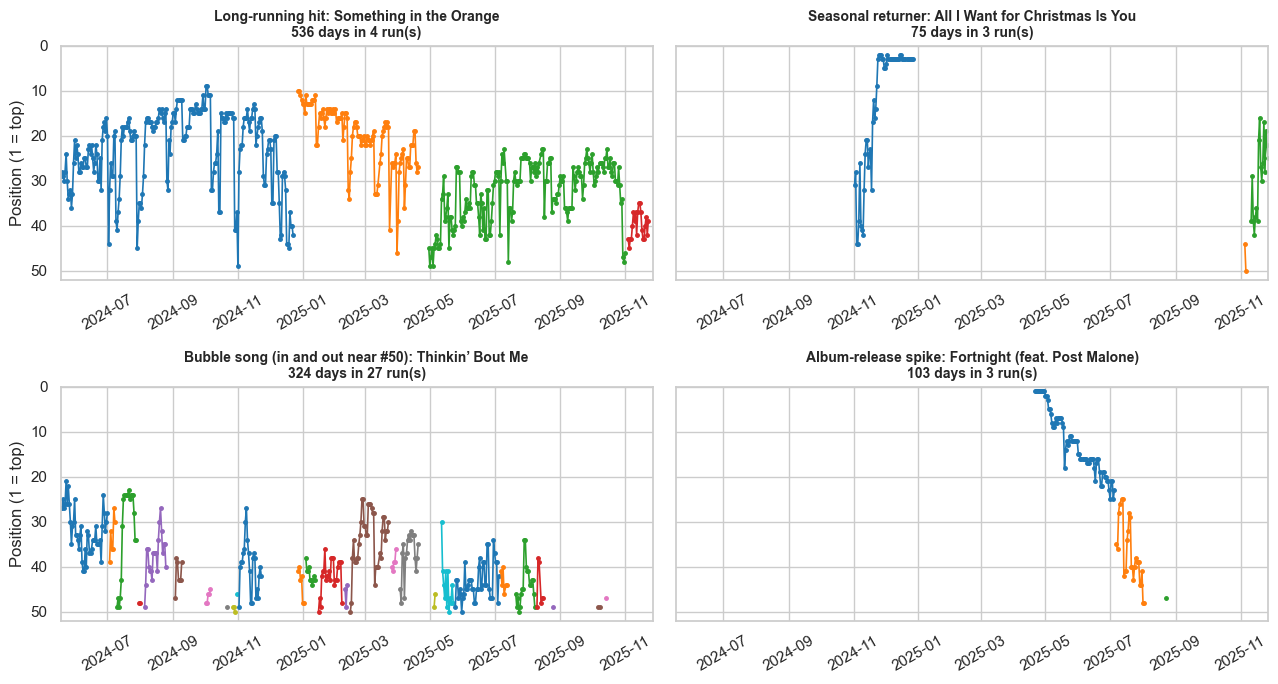

[Step 2.3] Added chart-run columns (stint_no, stint_key, days_in_stint, stint_length, is_stint_start, is_stint_end): rows 27,750 -> 27,750 | rows affected: 0


In [9]:
df = df.sort_values(["track_id", "date"]).reset_index(drop=True)          # all later steps rely on this order

distance = df.groupby("track_id")["snapshot_index"].diff()               # snapshots since this song's previous appearance
starts_new_run = distance.isna() | (distance != 1)                       # first appearance, or a break in the streak
df["stint_no"]  = starts_new_run.astype(int).groupby(df["track_id"]).cumsum()          # run number: 1, 2, 3 ... per song
df["stint_key"] = df["track_id"].astype(str) + "-" + df["stint_no"].astype(str)        # unique id of one run

df["days_in_stint"] = df.groupby("stint_key").cumcount() + 1                          # day 1, 2, 3 ... inside the run
df["stint_length"]  = df.groupby("stint_key")["date"].transform("size")               # total length of that run
df["is_stint_start"] = df["days_in_stint"] == 1
df["is_stint_end"]   = df["days_in_stint"] == df["stint_length"]

runs_per_song = df.groupby("track_id")["stint_no"].max()
run_lengths   = df.groupby("stint_key").size()
print(f"Runs in total              : {df['stint_key'].nunique():,}")
print(f"Songs with exactly one run : {(runs_per_song == 1).sum()} | with more than one run: {(runs_per_song > 1).sum()} | maximum runs: {runs_per_song.max()}")
print(f"Median run length          : {run_lengths.median():.0f} days | one-day runs: {(run_lengths == 1).sum()} ({(run_lengths == 1).mean():.1%} of runs)")

# Four contrasting journeys (rank 1 is at the TOP of each chart; each colour is one run)
examples = {
    "Long-running hit":                  "Something in the Orange",
    "Seasonal returner":                 "All I Want for Christmas Is You",
    "Bubble song (in and out near #50)": "Thinkin",
    "Album-release spike":               "Fortnight",
}
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey=True)
palette = sns.color_palette("tab10")
for ax, (label, title_start) in zip(axes.ravel(), examples.items()):
    tid = df.loc[df["song_clean"].str.startswith(title_start), "track_id"].iloc[0]
    song = df[df["track_id"] == tid]
    for k, (run_no, part) in enumerate(song.groupby("stint_no")):
        ax.plot(part["date"], part["position"], marker="o", ms=2.5, lw=1.2, color=palette[k % 10])
    ax.set_title(f"{label}: {song['song_clean'].iloc[0]}\n{len(song)} days in {song['stint_no'].max()} run(s)", fontsize=10)
    ax.set_xlim(df["date"].min(), df["date"].max())
    ax.set_ylim(52, 0)                                                   # inverted: #1 at the top
    ax.tick_params(axis="x", labelrotation=30)
axes[0, 0].set_ylabel("Position (1 = top)")
axes[1, 0].set_ylabel("Position (1 = top)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p2_chart_journeys.png", dpi=150)
plt.show()

log_step("2.3", "Added chart-run columns (stint_no, stint_key, days_in_stint, stint_length, is_stint_start, is_stint_end)",
         len(df), len(df), 0, note="A run = consecutive snapshots; any absence starts a new run")

### Step 2.4 - One song, one identity: title, artist credit and label (decisions #6, #7, #8)

**What this code is:** Three small repairs that make sure every `track_id` has exactly one title, one artist credit and one display label.

1. **Title:** if a song was spelled two ways, keep the most common spelling.
2. **Artist credit:** a song can be credited to `Post Malone` on some days and to `Post Malone & Morgan Wallen` on others. We keep the **fullest credit** (the one with the most artists) so that featured artists get credit for the songs they are on.
3. **Label:** a readable name such as `Last Night by Morgan Wallen`, used in charts and dashboards.

**Why we need it:** In Phase 1 we merged these credit variants into one `track_id`, but the daily rows still showed the different credits. A song must have one stable description, otherwise its artist table and its dashboard label would change from day to day.

**What will happen:** Python builds the fullest credit per song, replaces the artist columns with the new, constant values (`artist_credit`, `artists_all`, `artist_count`, `primary_artist`), creates `track_label` and proves that each label points to exactly one song.

**Expected outcome:** 28 songs had more than one credit before; after this step every song has one (and 2 songs had two title spellings; now 0). For example *I Had Some Help* now carries the single credit `Post Malone & Morgan Wallen` for all its days. The uniqueness test passes.

**Motive:** Stable identity. Every table we build next (song, artist, bridge) depends on it.

In [10]:
# 1) Title: the most common spelling for each song
titles_before = df.groupby("track_id")["song_clean"].nunique()
df["song_clean"] = df.groupby("track_id")["song_clean"].transform(lambda s: s.mode().iloc[0])

# 2) Artist credit: for every song keep the credit with the most artists (ties: more days, then most recent)
credits = (df.groupby(["track_id", "artists_all"])
             .agg(artist_credit=("artist_clean", "first"), artist_count=("artist_count", "first"),
                  days=("date", "size"), last_seen=("date", "max"))
             .reset_index())
credits_per_song = credits.groupby("track_id").size()
fullest = (credits.sort_values(["track_id", "artist_count", "days", "last_seen"], ascending=[True, False, False, False])
                  .drop_duplicates("track_id").set_index("track_id"))

df = df.drop(columns=["artist_clean", "primary_artist", "artist_count", "artists_all", "track_credit"])
df["artist_credit"]  = df["track_id"].map(fullest["artist_credit"])
df["artists_all"]    = df["track_id"].map(fullest["artists_all"])
df["artist_count"]   = df["track_id"].map(fullest["artist_count"]).astype(int)
df["primary_artist"] = df["artists_all"].str.split(" | ", regex=False).str[0]      # the first (lead) artist

# 3) A readable label, e.g. "Last Night by Morgan Wallen"
df["track_label"] = df["song_clean"] + " by " + df["artist_credit"]
assert df.groupby("track_label")["track_id"].nunique().max() == 1, "two different songs share one label"
assert df.groupby("track_id")["artist_credit"].nunique().max() == 1

print(f"Songs with more than one title spelling: {(titles_before > 1).sum()} -> now 0")
print(f"Songs with more than one artist credit : {(credits_per_song > 1).sum()} -> now 0")
print("\nExamples of songs whose credit was unified:")
unified = credits_per_song[credits_per_song > 1].index[:5]
display(df[df["track_id"].isin(unified)].drop_duplicates("track_id")[["track_id", "song_clean", "artist_credit", "artist_count", "primary_artist"]])

log_step("2.4", "One title, one fullest artist credit and one label per song",
         len(df), len(df), int(df["track_id"].isin(credits_per_song[credits_per_song > 1].index).sum()),
         note="Rows whose song had more than one credit before the unification")

Songs with more than one title spelling: 2 -> now 0
Songs with more than one artist credit : 28 -> now 0

Examples of songs whose credit was unified:


,track_id,song_clean,artist_credit,artist_count,primary_artist
662,3,All My Life (feat. J. Cole),Lil Durk & J. Cole,2,Lil Durk
758,4,un x100to,Grupo Frontera & Bad Bunny,2,Grupo Frontera
1974,13,PRC,Peso Pluma & Natanael Cano,2,Peso Pluma
5984,58,AMERICA HAS A PROBLEM (feat. Kendrick Lamar),Beyoncé & Kendrick Lamar,2,Beyoncé
6193,70,Popular (with Playboi Carti & Madonna),The Weeknd & Playboi Carti & Madonna,3,The Weeknd


[Step 2.4] One title, one fullest artist credit and one label per song: rows 27,750 -> 27,750 | rows affected: 1,137


### Step 2.5 - Repair the popularity zeros (decision #4, refined)

**What this code is:** A three-level repair rule that replaces the 189 `popularity = 0` values with a sensible estimate and records *how* each value was fixed. The original `popularity` column is never touched; the repaired values go into the new column `popularity_clean`.

**Why we need it:** Zero is not a real score for a song sitting in the Top 50. First we test our explanation: if zeros are "not yet computed" scores, they should sit on a song's **first chart day**. Then we repair them in the most honest order:

1. **Level 1 - same run:** use the nearest real values from the **same chart run** (straight-line interpolation; a zero on the first day takes the next day's value).
2. **Level 2 - same song:** if the whole run is zero, use the **song's median** from its other runs.
3. **Level 3 - give up:** if the song has *no* real value anywhere, leave it empty. We never invent a number from nothing.

**What will happen:** Python measures how many zeros are first-day rows, applies the three levels, records the method in `popularity_fill_method` and draws the daily average popularity before and after the repair.

**Expected outcome:** **166 of 189 zeros (88%)** are on a song's first chart day, although first days are only 3.4% of all rows. The repair: **168 rows** fixed at level 1, **3 rows** at level 2 and **18 rows** left empty. The "before" line in the chart has deep, sharp dips on release days (down to the 45-50 range); the "after" line keeps only small dips, which are genuine (brand-new songs really do start with lower scores).

**Motive:** Without the repair, averages and trend lines would show false "popularity crashes" on every big album-release day. With it, we also keep an audit trail (`popularity_fill_method`) so the analysis can exclude the 18 unfilled rows if needed.

Rows with popularity = 0                : 189
... that are a song's very first day    : 166 (88%)
For comparison, first days are only 3.4% of all rows -> zeros are tied to NEW releases, not random

How each popularity value was obtained:
popularity_fill_method
original               27561
interpolated_in_run      168
unfilled                  18
song_median                3

Average popularity before: 87.66 | after: 88.19


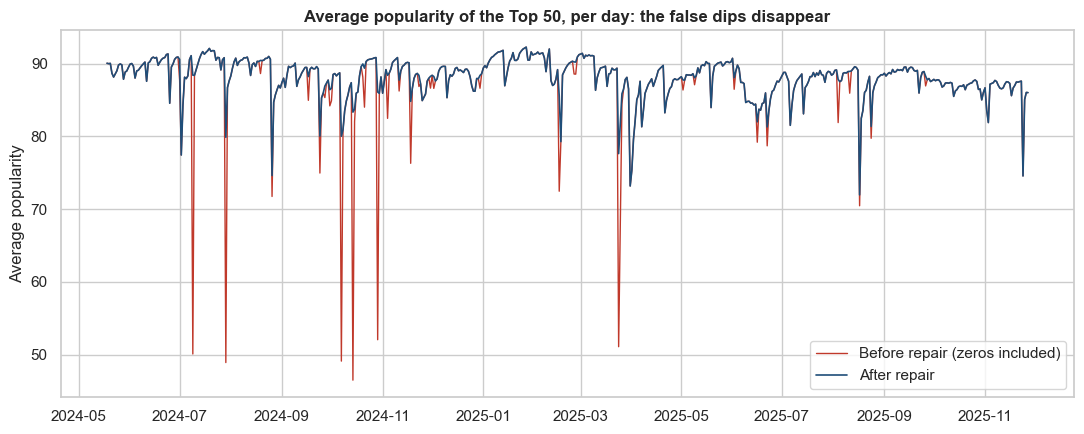

[Step 2.5] Popularity zeros treated as missing and repaired (run interpolation -> song median -> unfilled): rows 27,750 -> 27,750 | rows affected: 189


In [11]:
zero = df["popularity"] == 0
first_day_of_song = (df["stint_no"] == 1) & (df["days_in_stint"] == 1)       # the very first time a song is on the chart

print(f"Rows with popularity = 0                : {zero.sum()}")
print(f"... that are a song's very first day    : {(zero & first_day_of_song).sum()} ({(zero & first_day_of_song).sum() / zero.sum():.0%})")
print(f"For comparison, first days are only {first_day_of_song.mean():.1%} of all rows -> zeros are tied to NEW releases, not random\n")

# --- the repair ---
real_only = df["popularity"].where(~zero)                                     # zeros become NaN ("missing")
level1_values = real_only.groupby(df["stint_key"]).transform(
    lambda s: s.interpolate(method="linear", limit_direction="both"))        # nearest real values inside the same run
song_median = real_only.groupby(df["track_id"]).transform("median")          # median of the song's real values

df["popularity_clean"] = level1_values
use_level2 = zero & level1_values.isna() & song_median.notna()
df.loc[use_level2, "popularity_clean"] = song_median[use_level2]
df["popularity_clean"] = df["popularity_clean"].round(2)

df["popularity_was_zero"] = zero
df["popularity_fill_method"] = np.select(
    [(zero & level1_values.notna()).to_numpy(), use_level2.to_numpy(), zero.to_numpy()],
    ["interpolated_in_run", "song_median", "unfilled"], default="original")

print("How each popularity value was obtained:")
print(df["popularity_fill_method"].value_counts().to_string())
print(f"\nAverage popularity before: {df['popularity'].mean():.2f} | after: {df['popularity_clean'].mean():.2f}")

# --- before / after chart ---
daily_pop = df.groupby("date").agg(before=("popularity", "mean"), after=("popularity_clean", "mean"))
fig, ax = plt.subplots()
ax.plot(daily_pop.index, daily_pop["before"], color=COLORS["bad"], lw=1, label="Before repair (zeros included)")
ax.plot(daily_pop.index, daily_pop["after"], color=COLORS["primary"], lw=1.2, label="After repair")
ax.set_title("Average popularity of the Top 50, per day: the false dips disappear")
ax.set_ylabel("Average popularity")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p2_popularity_repair.png", dpi=150)
plt.show()

log_step("2.5", "Popularity zeros treated as missing and repaired (run interpolation -> song median -> unfilled)",
         len(df), len(df), int(zero.sum()),
         note="original column kept; method recorded in popularity_fill_method; unfilled rows stay empty")

### Step 2.6 - Album type, release format and album-size bands (decisions #5 and #11)

**What this code is:** Two new text columns. `release_format` groups `album_type` into **Single** versus **Album** (the rare `compilation` joins Album). `release_size_band` groups `total_tracks` into readable bands: 1 track, 2-3, 4-7, 8-15, 16-40, 41+.

**Why we need it:** The brief asks for "Single vs album" and "album size vs success". Statistical tests need groups that are big enough: only 42 rows are compilations, which is too few to test on their own. Phase 1 also showed that `single` does not always mean one track, so we keep both columns: the *type* and the *size*.

**What will happen:** Python creates both columns and prints a small cross-table.

**Expected outcome:** `release_format` has **8,001 Single rows and 19,749 Album rows** (the 42 compilation rows join Album). The size bands show **6,233 rows from one-track releases** and only **19 rows from releases with 41 or more tracks**. The original `album_type` stays untouched (it still has 3 values).

**Motive:** Analysis-ready categories, with the original information preserved for anyone who wants the finer detail.

In [12]:
df["release_format"] = np.where(df["album_type"] == "single", "Single", "Album")      # compilation joins Album

size_bins   = [0, 1, 3, 7, 15, 40, 1000]
size_labels = ["1 track", "2-3", "4-7", "8-15", "16-40", "41+"]
df["release_size_band"] = pd.cut(df["total_tracks"], bins=size_bins, labels=size_labels).astype(str)

print("album_type -> release_format (rows):")
display(pd.crosstab(df["album_type"], df["release_format"]))
print("release_size_band (rows):")
print(df["release_size_band"].value_counts().reindex(size_labels).to_string())

log_step("2.6", "Added release_format (Single/Album) and release_size_band", len(df), len(df), len(df),
         note="album_type kept unchanged; compilation merged into Album only inside release_format")

album_type -> release_format (rows):


release_format,Album,Single
album_type,,
album,19707,0
compilation,42,0
single,0,8001


release_size_band (rows):
release_size_band
1 track     6233
2-3         1026
4-7          908
8-15        9216
16-40      10348
41+           19
[Step 2.6] Added release_format (Single/Album) and release_size_band: rows 27,750 -> 27,750 | rows affected: 27,750


### Step 2.7 - Review the cleaning log and save a checkpoint

**What this code is:** A table of every cleaning action so far, followed by saving the cleaned (but not yet feature-rich) data as a checkpoint file.

**Why we need it:** The log is the evidence that the data was cleaned in a controlled way. The checkpoint (`playlist_clean.parquet`) lets Phase 3 (the ETL pipeline) start from "clean data" without re-running the notebook.

**What will happen:** Python displays the log and writes `data/interim/playlist_clean.parquet`.

**Expected outcome:** A table with 7 rows (steps 1.6 to 2.6) and the message `Checkpoint saved: 27,750 rows`.

**Motive:** Good pipelines have checkpoints between stages (the "silver layer": cleaned but not yet enriched).

In [13]:
display(pd.DataFrame(cleaning_log))

checkpoint_path = INTERIM_DIR / "playlist_clean.parquet"
df.to_parquet(checkpoint_path, index=False)
print(f"\nCheckpoint saved: {len(df):,} rows x {df.shape[1]} columns -> {checkpoint_path.relative_to(PROJECT_ROOT)}")

,step,rule,rows_before,rows_after,rows_affected,note
0,1.6,Calendar kept exactly as provided; evidence suggests it ...,27800,27800,0,Median gap between real release and first chart appearan...
1,2.1,Keep the latest block of a double-snapshot date (2025-03...,27800,27750,50,Decision #2 of the Phase 1 log
2,2.2,Added snapshot_index and days_since_prev_snapshot (time ...,27750,27750,0,"Decision #3: 4 missing calendar days are kept as gaps, n..."
3,2.3,"Added chart-run columns (stint_no, stint_key, days_in_st...",27750,27750,0,A run = consecutive snapshots; any absence starts a new run
4,2.4,"One title, one fullest artist credit and one label per song",27750,27750,1137,Rows whose song had more than one credit before the unif...
5,2.5,Popularity zeros treated as missing and repaired (run in...,27750,27750,189,original column kept; method recorded in popularity_fill...
6,2.6,Added release_format (Single/Album) and release_size_band,27750,27750,27750,album_type kept unchanged; compilation merged into Album...



Checkpoint saved: 27,750 rows x 35 columns -> data\interim\playlist_clean.parquet


## Section 3 - Daily features (every row = one song on one day)

### Step 3.1 - Calendar, rank-tier and duration features

**What this code is:** A batch of simple but useful new columns. *Calendar* columns (year, month, quarter, week, weekday, weekend flag). *Rank* columns (`rank_tier`, `in_top10`, `in_top20`, `is_number_one`, `chart_points`). Plus `duration_min` (the brief's "Duration in minutes") and `is_collab`.

**Why we need it:** Analysts constantly ask "does it matter which weekday?", "how does a Top 10 song differ from a Top 50 song?", "how long is a typical hit?". Having these columns ready means each question is one line of code later (and one drag-and-drop in Power BI). `chart_points = 51 - position` turns a rank into a score where **#1 is worth 50 points and #50 is worth 1**; we use it for the Artist Dominance Index.

**What will happen:** Python creates 16 new columns from existing ones and prints a few sample rows and the rank-tier counts.

**Expected outcome:** `rank_tier` has exactly **5,550 rows in Top 10, 5,550 in 11-20 and 16,650 in 21-50** (555 days times 10, 10 and 30 ranks). The sample rows show `duration_min` next to `duration_ms`.

**Motive:** Feature engineering is the art of putting the question's answer one step closer to the data.

In [14]:
# ---- Calendar features ----
df["year"]        = df["date"].dt.year
df["month"]       = df["date"].dt.month
df["month_name"]  = df["date"].dt.month_name()
df["year_month"]  = df["date"].dt.strftime("%Y-%m")                  # text like 2024-05, sorts correctly
df["quarter"]     = df["date"].dt.quarter
df["iso_week"]    = df["date"].dt.isocalendar().week.astype(int)
df["day_of_week"] = df["date"].dt.dayofweek + 1                      # Monday = 1 ... Sunday = 7
df["day_name"]    = df["date"].dt.day_name()
df["is_weekend"]  = df["day_of_week"] >= 6

# ---- Rank features ----
df["rank_tier"]     = pd.cut(df["position"], bins=[0, 10, 20, 50], labels=["Top 10", "11-20", "21-50"]).astype(str)
df["in_top10"]      = df["position"] <= 10
df["in_top20"]      = df["position"] <= 20
df["is_number_one"] = df["position"] == 1
df["chart_points"]  = 51 - df["position"]                            # rank 1 = 50 points ... rank 50 = 1 point

# ---- Other ----
df["duration_min"] = (df["duration_ms"] / 60_000).round(3)           # the brief's "Duration in minutes"
df["is_collab"]    = df["artist_count"] > 1                          # two or more artists on the song

print("Rows per rank tier:")
print(df["rank_tier"].value_counts().reindex(["Top 10", "11-20", "21-50"]).to_string())
print(f"\nTotal chart points in the dataset: {df['chart_points'].sum():,}  (= 555 days x 1,275 points per day)")
display(df[["date", "day_name", "position", "rank_tier", "chart_points", "duration_ms", "duration_min", "is_collab"]].sample(6, random_state=7))

Rows per rank tier:
rank_tier
Top 10     5550
11-20      5550
21-50     16650

Total chart points in the dataset: 707,625  (= 555 days x 1,275 points per day)


,date,day_name,position,rank_tier,chart_points,duration_ms,duration_min,is_collab
16388,2025-10-03,Friday,21,21-50,30,210688,3.51,False
25058,2025-07-17,Thursday,22,21-50,29,284903,4.75,True
25145,2025-07-26,Saturday,12,11-20,39,233333,3.89,False
18237,2025-07-24,Thursday,45,21-50,6,159245,2.65,False
22579,2025-08-18,Monday,7,Top 10,44,274192,4.57,False
9948,2025-02-22,Saturday,6,Top 10,45,227195,3.79,False


### Step 3.2 - Rank movement: up, down, same, new entry, re-entry

**What this code is:** For every row we look back at where the same song was on the previous snapshot and calculate `rank_change = previous position - current position`. A **positive** number means the song *climbed* (it moved toward #1), a negative number means it *fell*. We also build `rank_gain_7d` (the change over a week) and a label called `movement`.

**Why we need it:** "Rank movement patterns" and "fast risers and slow decliners" are in the brief. Both start from the day-to-day change. The sign convention is deliberate: *positive = good*, so charts read naturally.

**What will happen:** Python looks up each song's previous position **only if the song was on the immediately preceding snapshot** (otherwise the song is entering, and there is nothing to compare with). It then labels every row and draws a histogram of the daily changes.

**Expected outcome:** Movement counts: **Down 9,291 | Up 8,293 | Same 8,185 | Re-entry 1,037 | New entry 894 | Chart start 50**. About **75% of day-to-day moves are within 3 places**; the biggest single-day jumps are +48 and -42. More than half of all entries (53.7%) are *re-entries*, not brand-new songs.

**Motive:** This is the raw material for the "entry vs exit behavior" and "fast risers / slow decliners" analysis in Phase 4.

Movement labels:
movement
Down           9291
Up             8293
Same           8185
Re-entry       1037
New entry       894
Chart start      50

Day-to-day moves within +-3 places: 75.2% | biggest climb: 48 | biggest fall: -42
Entries that are re-entries: 53.7%


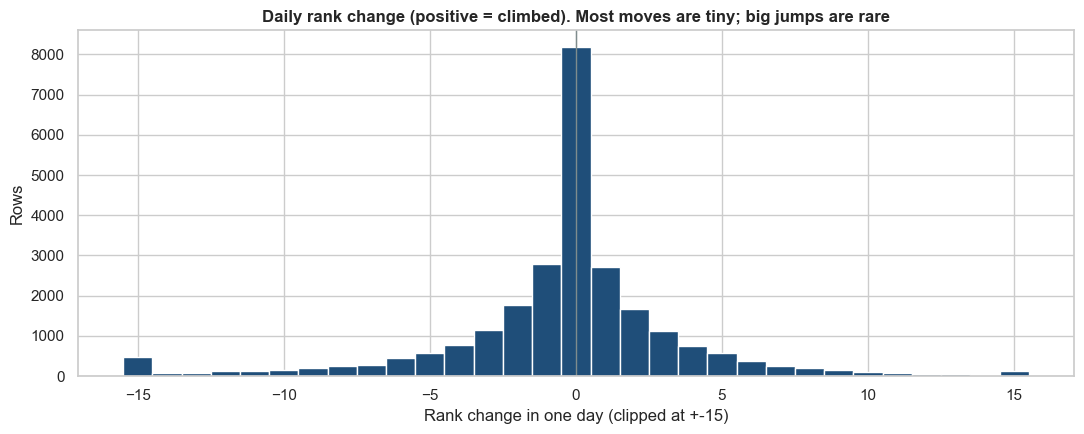

In [15]:
by_song = df.groupby("track_id")                                          # df is sorted by song, then date

previous_position = by_song["position"].shift(1)                          # the song's position on its previous appearance
previous_snapshot = by_song["snapshot_index"].shift(1)
was_on_previous_snapshot = (df["snapshot_index"] - previous_snapshot) == 1    # only a real "yesterday" counts

df["prev_position"] = previous_position.where(was_on_previous_snapshot)
df["rank_change"]   = df["prev_position"] - df["position"]                # positive = climbed, negative = fell

# Change over one week (position 7 snapshots ago minus position now), only when present on all 7 snapshots in between
position_7_ago = by_song["position"].shift(7)
snapshot_7_ago = by_song["snapshot_index"].shift(7)
df["rank_gain_7d"] = (position_7_ago - df["position"]).where((df["snapshot_index"] - snapshot_7_ago) == 7)

# A readable label for every row
conditions = [df["is_stint_start"] & (df["snapshot_index"] == 1),        # already on the chart when our data begins
              df["is_stint_start"] & (df["stint_no"] == 1),              # first appearance in our data
              df["is_stint_start"],                                      # came back after being away
              df["rank_change"] > 0, df["rank_change"] < 0, df["rank_change"] == 0]
labels = ["Chart start", "New entry", "Re-entry", "Up", "Down", "Same"]
df["movement"] = np.select([c.to_numpy() for c in conditions], labels, default="Unknown")
assert (df["movement"] != "Unknown").all(), "some rows could not be labelled"

print("Movement labels:")
print(df["movement"].value_counts().to_string())
moves = df["rank_change"].dropna()
print(f"\nDay-to-day moves within +-3 places: {(moves.abs() <= 3).mean():.1%} | biggest climb: {int(moves.max())} | biggest fall: {int(moves.min())}")
entries = df["movement"].isin(["New entry", "Re-entry"]).sum()
print(f"Entries that are re-entries: {(df['movement'] == 'Re-entry').sum() / entries:.1%}")

fig, ax = plt.subplots()
ax.hist(moves.clip(-15, 15), bins=np.arange(-15.5, 16.5, 1), color=COLORS["primary"])
ax.axvline(0, color=COLORS["grey"], lw=1)
ax.set_title("Daily rank change (positive = climbed). Most moves are tiny; big jumps are rare")
ax.set_xlabel("Rank change in one day (clipped at +-15)")
ax.set_ylabel("Rows")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p2_rank_change_hist.png", dpi=150)
plt.show()

### Step 3.3 - Chart-life features: exits, chart day number and calendar age

**What this code is:** Three more columns. `exits_next_snapshot` marks the last day of a run when the song really disappears afterwards. `chart_day_number` counts how many days the song has spent on the chart *so far* (1 = its debut day). `calendar_age_days` counts calendar days since its very first appearance.

**Why we need it:** An *exit* is only real if the song is missing on the next snapshot. A run that ends on the last date of our data has **not** ended, we just stop watching (this is called *censoring*, and it matters a lot in Section 4). `chart_day_number` and `calendar_age_days` let us study how rank and popularity change as a song ages on the chart.

**What will happen:** Python creates the three columns and checks a built-in consistency rule: **total entries must equal total exits**, because every date has exactly 50 rows (for each song that enters, another must leave).

**Expected outcome:** **1,931 entries** (894 new + 1,037 re-entries) and **1,931 exits**. The check prints `OK`.

**Motive:** A free integrity test. If the numbers did not match, we would know there is a bug in the run logic.

In [16]:
last_snapshot = df["snapshot_index"].max()
df["exits_next_snapshot"] = df["is_stint_end"] & (df["snapshot_index"] < last_snapshot)    # a real exit, not just the end of our data

df["chart_day_number"]  = df.groupby("track_id").cumcount() + 1                             # 1 = debut day, 2 = second chart day ...
first_seen_per_song     = df.groupby("track_id")["date"].transform("min")
df["calendar_age_days"] = (df["date"] - first_seen_per_song).dt.days                        # days since the very first appearance

n_entries = int(df["movement"].isin(["New entry", "Re-entry"]).sum())
n_exits   = int(df["exits_next_snapshot"].sum())
print(f"Entries (new + re-entries): {n_entries:,} | Exits: {n_exits:,}")
assert n_entries == n_exits, "entries and exits must match when every day has exactly 50 rows"
print("OK  entries equal exits, exactly as they must")
print(f"\nRuns that are still going on the last snapshot (not exits): {int((df['is_stint_end'] & (df['snapshot_index'] == last_snapshot)).sum())}")

Entries (new + re-entries): 1,931 | Exits: 1,931
OK  entries equal exits, exactly as they must

Runs that are still going on the last snapshot (not exits): 50


### Step 3.4 - Rolling features: the Popularity Trend Score and rank smoothing

**What this code is:** Three *rolling* columns, each calculated over a window of 7 chart days **inside the same run**: `popularity_trend_7d` (the brief's **Popularity Trend Score**: the 7-day average of `popularity_clean`), `avg_rank_7d` (7-day average position) and `rank_volatility_7d` (7-day standard deviation of position).

**Why we need it:** Daily values are noisy. A rolling average smooths the noise so you can see the real direction (rising, falling, steady). The rolling standard deviation shows *local* instability: a song can be steady for weeks and then suddenly jumpy. Windows never cross a gap between runs, because averaging the last day of one run with the first day of a run months later would be meaningless.

**What will happen:** Python applies pandas' `rolling` function to each run separately. The first days of a run use whatever days exist so far (the volatility needs at least 3 days). A two-panel chart shows one song's raw lines against the smoothed lines.

**Expected outcome:** In the chart the grey lines are jumpy and the coloured lines are smooth. Each run is drawn separately, so there are no lines across the gaps when the song was off the chart. The missing-value count shows **18** empty `popularity_trend_7d` values (exactly the 18 unfilled popularity rows), **0** empty `avg_rank_7d` values and **3,511** empty `rank_volatility_7d` values (the first two days of every run, where a standard deviation of fewer than 3 values would be meaningless).

**Motive:** Smoothed trend lines are what stakeholders read in dashboards; the raw lines are what analysts check against.

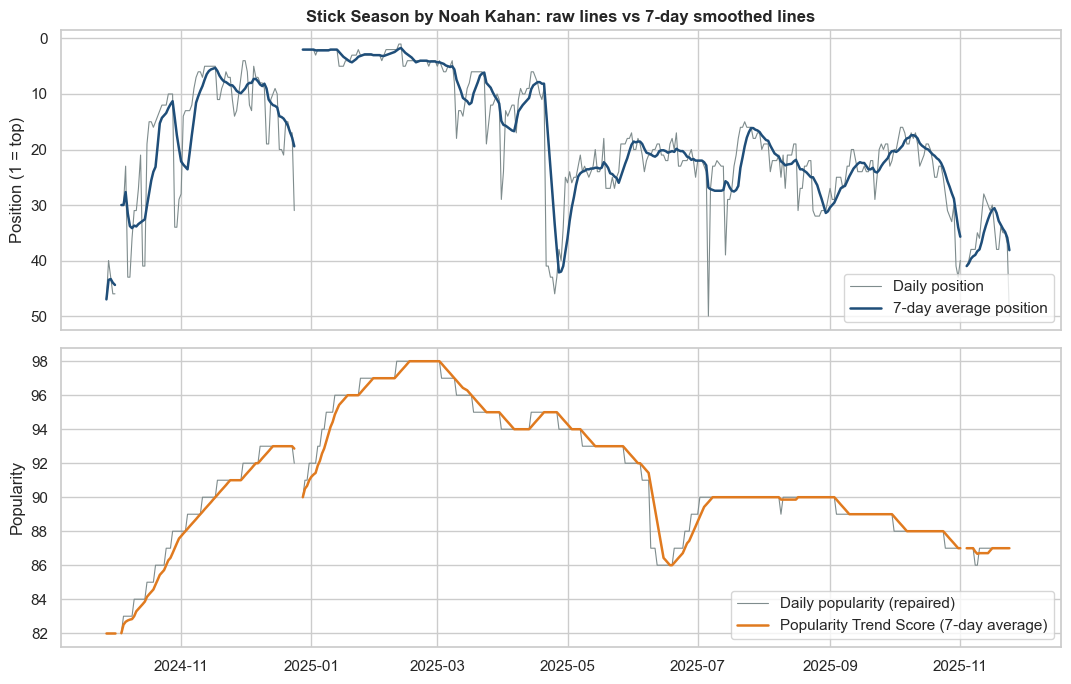

Missing values in the new rolling columns:
popularity_trend_7d      18
avg_rank_7d               0
rank_volatility_7d     3511

The table now has 61 columns.
[Step 3.x] Added daily features (calendar, rank tiers, movement, chart life, rolling trend): rows 27,750 -> 27,750 | rows affected: 27,750


In [17]:
by_run = df.groupby("stint_key")                                          # every calculation stays inside one chart run

df["popularity_trend_7d"] = by_run["popularity_clean"].transform(lambda s: s.rolling(7, min_periods=1).mean()).round(2)
df["avg_rank_7d"]         = by_run["position"].transform(lambda s: s.rolling(7, min_periods=1).mean()).round(2)
df["rank_volatility_7d"]  = by_run["position"].transform(lambda s: s.rolling(7, min_periods=3).std()).round(2)


def plot_runs(ax, data, column, label, **style):
    """Draw one line per chart run, so nothing is drawn across a period when the song was off the chart."""
    for k, (_, part) in enumerate(data.groupby("stint_no")):
        ax.plot(part["date"], part[column], label=label if k == 0 else None, **style)


example = df[df["song_clean"].str.startswith("Stick Season")]
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
plot_runs(axes[0], example, "position", "Daily position", color=COLORS["grey"], lw=0.8)
plot_runs(axes[0], example, "avg_rank_7d", "7-day average position", color=COLORS["primary"], lw=1.8)
axes[0].invert_yaxis()                                                    # rank 1 at the top
axes[0].set_ylabel("Position (1 = top)")
axes[0].set_title(f"{example['track_label'].iloc[0]}: raw lines vs 7-day smoothed lines")
axes[0].legend(loc="lower right")

plot_runs(axes[1], example, "popularity_clean", "Daily popularity (repaired)", color=COLORS["grey"], lw=0.8)
plot_runs(axes[1], example, "popularity_trend_7d", "Popularity Trend Score (7-day average)", color=COLORS["accent"], lw=1.8)
axes[1].set_ylabel("Popularity")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p2_rolling_features.png", dpi=150)
plt.show()

new_daily_cols = ["popularity_trend_7d", "avg_rank_7d", "rank_volatility_7d"]
print("Missing values in the new rolling columns:")
print(df[new_daily_cols].isna().sum().to_string())
print(f"\nThe table now has {df.shape[1]} columns.")

log_step("3.x", "Added daily features (calendar, rank tiers, movement, chart life, rolling trend)",
         len(df), len(df), len(df), note="No rows removed; only new columns")

## Section 4 - Track features: one row per song (the KPI table)

### Step 4.1 - The core KPIs from the brief

**What this code is:** One big `groupby("track_id")` that collapses the 27,750 daily rows into **one row per song** (944 rows) and calculates the KPIs from the brief:

- **Days on Chart** (`days_on_chart`): how many snapshots the song appeared on
- **Average Rank** (`avg_rank`), **Best Rank** (`best_rank`), plus median and worst rank
- **Rank Volatility Index** (`rank_volatility_index`): the standard deviation of the song's daily rank
- **Popularity** (`avg_popularity`, `peak_popularity`, `popularity_std` = stability)
- Top-10 days, Top-20 days, days at #1, total `chart_points`, number of runs

We also add one extra volatility measure, `avg_daily_rank_move` (the average size of the day-to-day change), for a reason explained below.

**Why we need it:** The whole project is about *songs*, not rows. A row says "this song was #7 on 14 June"; a KPI says "this song averaged #19 over 90 days and swung by 8 places". Two volatility numbers are needed because they answer different questions: the **standard deviation of rank** captures how widely the song's position *spread* over its whole life (a song that slowly slides from #5 to #45 scores high), while the **average daily move** captures *day-to-day jumpiness* (that same slow slider scores low). Reading both avoids a classic mistake: mistaking a trend for instability.

**What will happen:** Python aggregates, rounds the results and prints the 10 songs with the most days on the chart.

**Expected outcome:** **944 rows**. The top song is *Something in the Orange* with **536 days**, then *Last Night* (492) and *I Remember Everything* (446). The median song stays only **7 days**, the mean is 29.4: a few evergreens pull the average up. `rank_volatility_index` is empty for **150** songs that appeared only once (a standard deviation needs at least 2 values).

**Motive:** This is the table that Power BI and Streamlit will use for song rankings, longevity charts and scatter plots.

In [18]:
by_song = df.groupby("track_id")

songs = by_song.agg(
    track_label=("track_label", "first"),
    song_clean=("song_clean", "first"),
    artist_credit=("artist_credit", "first"),
    primary_artist=("primary_artist", "first"),
    artist_count=("artist_count", "first"),
    artists_all=("artists_all", "first"),
    days_on_chart=("date", "size"),                                        # KPI: Days on Chart
    avg_rank=("position", "mean"),                                         # KPI: Average Rank
    median_rank=("position", "median"),
    best_rank=("position", "min"),                                         # best = smallest number
    worst_rank=("position", "max"),
    rank_volatility_index=("position", "std"),                             # KPI: Rank Volatility Index
    avg_daily_rank_move=("rank_change", lambda s: s.abs().mean()),         # average size of the day-to-day change
    days_in_top10=("in_top10", "sum"),
    days_in_top20=("in_top20", "sum"),
    days_at_number_one=("is_number_one", "sum"),
    chart_points=("chart_points", "sum"),
    avg_popularity=("popularity_clean", "mean"),
    peak_popularity=("popularity_clean", "max"),
    popularity_std=("popularity_clean", "std"),                            # lower = more stable popularity
    n_runs=("stint_no", "max"),
)
songs["is_collab"] = songs["artist_count"] > 1
for col in ["avg_rank", "avg_daily_rank_move", "rank_volatility_index", "avg_popularity", "popularity_std"]:
    songs[col] = songs[col].round(2)

print(f"Songs: {len(songs):,}")
print("\ndays_on_chart: mean {:.1f} | median {:.0f} | max {}".format(songs["days_on_chart"].mean(), songs["days_on_chart"].median(), songs["days_on_chart"].max()))
print(f"Songs with an empty Rank Volatility Index (only 1 day on the chart): {songs['rank_volatility_index'].isna().sum()}")
print("\nTop 10 songs by Days on Chart:")
display(songs.sort_values("days_on_chart", ascending=False).head(10)
        [["track_label", "days_on_chart", "avg_rank", "best_rank", "rank_volatility_index", "avg_daily_rank_move", "n_runs"]])

Songs: 944

days_on_chart: mean 29.4 | median 7 | max 536
Songs with an empty Rank Volatility Index (only 1 day on the chart): 150

Top 10 songs by Days on Chart:


,track_label,days_on_chart,avg_rank,best_rank,rank_volatility_index,avg_daily_rank_move,n_runs
track_id,,,,,,,
29,Something in the Orange by Zach Bryan,536,26.30,9,9.35,2.88,4
2,Last Night by Morgan Wallen,492,22.62,1,14.55,2.74,10
248,I Remember Everything (feat. Kacey Musgraves) by Zach Bryan,446,13.90,1,9.89,1.82,3
6,"See You Again (feat. Kali Uchis) by Tyler, The Creator",444,29.38,4,11.81,2.94,19
308,Stick Season by Noah Kahan,414,18.29,1,11.36,2.20,5
16,Cruel Summer by Taylor Swift,388,16.92,1,13.63,2.48,10
491,Lose Control by Teddy Swims,329,23.50,5,8.65,2.35,3
27,Thinkin’ Bout Me by Morgan Wallen,324,39.02,21,7.14,2.92,27
519,Beautiful Things by Benson Boone,307,14.70,1,8.94,1.49,1


### Step 4.2 - Journey features: when, how long, how steady

**What this code is:** More song-level columns that describe the *shape* of a song's life on the chart: `first_seen`, `last_seen`, `span_days`, `presence_ratio`, `longest_run_days`, `entry_rank`, `exit_rank`, `peak_date` and `days_to_peak`.

**Why we need it:** `presence_ratio = days_on_chart / snapshots between first and last appearance`. It is **1.0** for a song that never left and close to **0** for a song that kept returning for short visits (a Christmas song, or a song bubbling around #50). `days_to_peak` tells us how fast songs reach their best rank: a spike song peaks on day 0, a slow-burner may need weeks. `entry_rank` and `exit_rank` show *where* songs enter and leave the chart.

**What will happen:** Python computes each column with grouped statistics (`min`, `max`, `first`, `last`, `idxmin`) and prints summary numbers.

**Expected outcome:** The median `presence_ratio` is **1.00** (most songs never leave until they are gone for good), but **93 songs (10%)** are below 0.5: the flickerers. **607 songs (64%)** reached their best rank on their very first day, which is typical of release-driven songs that enter high and then decay. The median entry rank is **23** and the median exit rank is **43**: songs tend to leave from the lower half of the chart.

**Motive:** These columns separate *staying power* from *flickering* and *spikes* from *slow burns*. That distinction is the heart of the "ranking stability vs volatility" question in the problem statement.

In [19]:
songs["first_seen"] = by_song["date"].min()
songs["last_seen"]  = by_song["date"].max()
songs["span_days"]  = (songs["last_seen"] - songs["first_seen"]).dt.days + 1          # calendar days from first to last appearance

first_idx, last_idx = by_song["snapshot_index"].min(), by_song["snapshot_index"].max()
songs["span_snapshots"] = last_idx - first_idx + 1                                    # snapshots from first to last appearance
songs["presence_ratio"] = (songs["days_on_chart"] / songs["span_snapshots"]).round(3) # 1.0 = never left the chart

songs["longest_run_days"] = df.groupby(["track_id", "stint_key"]).size().groupby("track_id").max()   # longest unbroken streak
songs["entry_rank"] = by_song["position"].first()                                     # position on the first day
songs["exit_rank"]  = by_song["position"].last()                                      # position on the last day

peak_rows = by_song["position"].idxmin()                                              # first row where the song hit its best rank
songs["peak_date"]    = df.loc[peak_rows, ["track_id", "date"]].set_index("track_id")["date"]
songs["days_to_peak"] = (songs["peak_date"] - songs["first_seen"]).dt.days

print("presence_ratio: median {:.2f} | songs below 0.5: {} ({:.0%})".format(
    songs["presence_ratio"].median(), (songs["presence_ratio"] < 0.5).sum(), (songs["presence_ratio"] < 0.5).mean()))
print("Songs that peaked on their very first day: {} ({:.0%})".format(
    (songs["days_to_peak"] == 0).sum(), (songs["days_to_peak"] == 0).mean()))
print("Median entry rank: {:.0f} | median exit rank: {:.0f}".format(songs["entry_rank"].median(), songs["exit_rank"].median()))

presence_ratio: median 1.00 | songs below 0.5: 93 (10%)
Songs that peaked on their very first day: 607 (64%)
Median entry rank: 23 | median exit rank: 43


### Step 4.3 - Censoring: which songs do we only see *partly*?

**What this code is:** Two True/False columns and a status label. `on_chart_at_window_start` marks songs that were already on the chart on the first snapshot (we do not know when they really arrived). `on_chart_at_window_end` marks songs still on the chart on the last snapshot (we do not know when they will leave). `run_status` summarizes both.

**Why we need it:** This is a subtle but very important idea, called **censoring**. For these songs, `days_on_chart` is only a *lower bound*: the true number is larger. If we compare "longest-lasting songs" without taking this into account, we mix complete stories with unfinished ones, and a song that debuted two weeks before our data ended can never look like a long-lasting hit. Phase 5 (hypothesis tests) and Phase 6 (survival analysis) will use these flags to compare songs fairly.

**What will happen:** Python compares each song's first and last date with the first and last date of the whole dataset.

**Expected outcome:** **50 songs** were already on the chart at the start, **50 songs** are still on the chart at the end, and none are both. The remaining **844** songs have a complete observed history. Notice the averages: complete-history songs average only **20.8 days**, while the two partly observed groups average **115.8** and **88.7** days. The partly observed groups look so much longer because a song that is on the chart at the very beginning or the very end of our window is more likely to be a long-runner (this is called *length bias*): another reason not to mix them.

**Motive:** Honest statistics. Our headline numbers must say which songs they are based on.

In [20]:
window_start, window_end = df["date"].min(), df["date"].max()

songs["on_chart_at_window_start"] = songs["first_seen"] == window_start        # arrived before our data begins
songs["on_chart_at_window_end"]   = songs["last_seen"] == window_end           # still there when our data ends

songs["run_status"] = np.select(
    [(songs["on_chart_at_window_start"] & songs["on_chart_at_window_end"]).to_numpy(),
     songs["on_chart_at_window_start"].to_numpy(),
     songs["on_chart_at_window_end"].to_numpy()],
    ["On chart the whole window", "Already on chart at start", "Still on chart at end"],
    default="Complete history observed")

print(songs["run_status"].value_counts().to_string())
print("\nAverage days on chart by status (only 'Complete history observed' is a fair longevity comparison):")
print(songs.groupby("run_status")["days_on_chart"].mean().round(1).to_string())

run_status
Complete history observed    844
Already on chart at start     50
Still on chart at end         50

Average days on chart by status (only 'Complete history observed' is a fair longevity comparison):
run_status
Already on chart at start   115.80
Complete history observed    20.80
Still on chart at end        88.70


### Step 4.4 - Song attributes: which value do we keep? (decision #9, refined)

**What this code is:** A fair test of two rules for choosing **one** value of `duration_ms`, `album_type`, `total_tracks` and `is_explicit` per song, because we know these change over time for some songs. Rule A: the **most recent** value (our Phase 1 plan). Rule B: the **most frequent** value (the value the song had on most of its chart days; ties go to the most recent). The cover image URL is cosmetic, so it simply takes the latest.

**Why we need it:** Decisions should be tested, not just announced. The test counts how many songs would get a *different* answer under the two rules. If the count is tiny, either rule is fine; if it is large, we must think harder.

**What will happen:** Python builds both versions, compares them and prints a small table. We then store rule B in the song table.

**Expected outcome:** Among 944 songs, 17 change `duration_ms`, 51 change `album_type`, 61 change `total_tracks` and 12 change `is_explicit`. The two rules disagree for only **8, 26, 30 and 3 songs** respectively (at most 3.2% of songs). We choose the **most frequent** value because it describes the version that was on the chart for most of the song's life, and it cannot be distorted by an odd value on the last day.

**Motive:** The decision log is a living document. Phase 1 planned "most recent"; the evidence now says "most frequent" is the more defensible choice, with almost no impact either way.

In [21]:
def most_frequent(values):
    """Return the most common value; if several tie, the one that appeared most recently."""
    counts = values.value_counts()
    tied = counts[counts == counts.max()].index
    return values[values.isin(tied)].iloc[-1]


descriptor_cols = ["duration_ms", "album_type", "total_tracks", "is_explicit"]
rule_b_frequent = by_song[descriptor_cols].agg(most_frequent)                      # Rule B: most frequent value
rule_a_recent   = by_song[descriptor_cols].last()                                  # Rule A: most recent value
changes_over_time = by_song[descriptor_cols].nunique() > 1

sensitivity = pd.DataFrame({
    "songs_whose_value_changes": changes_over_time.sum(),
    "rules_A_and_B_disagree":    (rule_b_frequent != rule_a_recent).sum(),
})
sensitivity["pct_of_all_songs"] = (sensitivity["rules_A_and_B_disagree"] / len(songs) * 100).round(1)
display(sensitivity)

for col in descriptor_cols:
    songs[col] = rule_b_frequent[col]                                              # keep the most frequent value
songs["duration_min"]       = (songs["duration_ms"] / 60_000).round(3)
songs["release_format"]     = np.where(songs["album_type"] == "single", "Single", "Album")
songs["release_size_band"]  = pd.cut(songs["total_tracks"], bins=size_bins, labels=size_labels).astype(str)
songs["album_cover_url"]    = by_song["album_cover_url"].last()                    # cosmetic: the latest artwork

print("Song-level release format:", songs["release_format"].value_counts().to_dict())
print("Song-level explicit share:", f"{songs['is_explicit'].mean():.1%}")

,songs_whose_value_changes,rules_A_and_B_disagree,pct_of_all_songs
duration_ms,17,8,0.80
album_type,51,26,2.80
total_tracks,61,30,3.20
is_explicit,12,3,0.30


Song-level release format: {'Album': 728, 'Single': 216}
Song-level explicit share: 52.4%


### Step 4.5 - Longevity classes and success flags

**What this code is:** Turning the number `days_on_chart` into five readable classes, plus two True/False success flags: `reached_top10` and `reached_number_one`.

**Why we need it:** Executives think in categories ("flash in the pan", "evergreen"), and classification models need a target to predict. The class boundaries follow the natural shape of the data: half of all songs stay less than 8 days and a small minority stays more than half a year.

| Class | Days on chart |
|---|---|
| Flash | 1-3 |
| Short | 4-14 |
| Medium | 15-60 |
| Long | 61-180 |
| Evergreen | 181+ |

**What will happen:** Python assigns the classes, draws a histogram of `days_on_chart` (log scale, because the distribution is extremely skewed) and a bar chart of the class sizes.

**Expected outcome:** **313 Flash, 313 Short, 195 Medium, 87 Long and 36 Evergreen songs**. 306 songs (32%) reached the Top 10 and 54 songs reached #1. The histogram falls steeply: most songs are short-lived, very few last long.

**Motive:** These classes will be the *dimensions* of the Power BI report and the *target labels* for the classification models in Phase 6.

longevity_class
Flash (1-3 days)    313
Short (4-14)        313
Medium (15-60)      195
Long (61-180)        87
Evergreen (181+)     36

Reached the Top 10: 306 (32%) | reached #1: 54


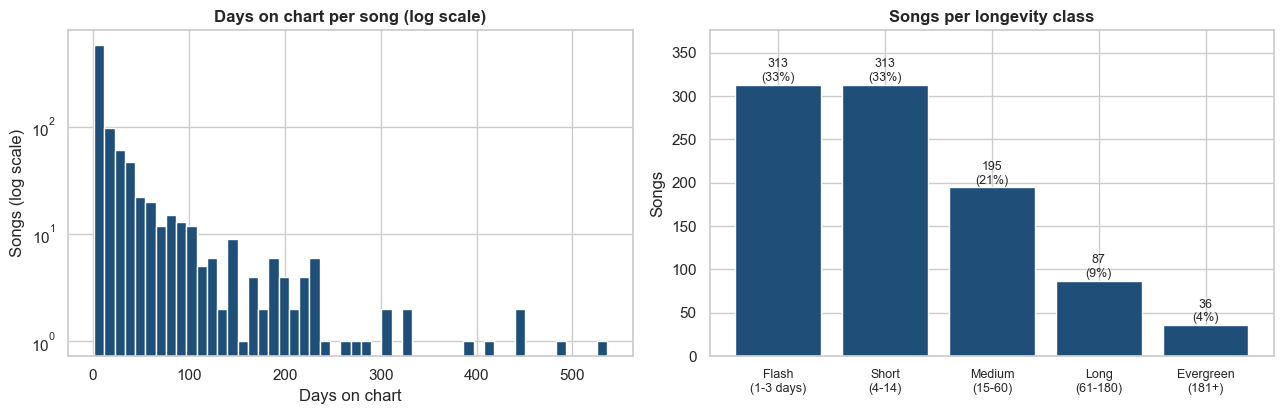

In [22]:
class_bins   = [0, 3, 14, 60, 180, np.inf]
class_labels = ["Flash (1-3 days)", "Short (4-14)", "Medium (15-60)", "Long (61-180)", "Evergreen (181+)"]
songs["longevity_class"]     = pd.cut(songs["days_on_chart"], bins=class_bins, labels=class_labels).astype(str)
songs["reached_top10"]       = songs["best_rank"] <= 10
songs["reached_number_one"]  = songs["best_rank"] == 1

class_counts = songs["longevity_class"].value_counts().reindex(class_labels)
print(class_counts.to_string())
print(f"\nReached the Top 10: {songs['reached_top10'].sum()} ({songs['reached_top10'].mean():.0%}) | reached #1: {songs['reached_number_one'].sum()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].hist(songs["days_on_chart"], bins=50, color=COLORS["primary"])
axes[0].set_yscale("log")
axes[0].set_title("Days on chart per song (log scale)")
axes[0].set_xlabel("Days on chart")
axes[0].set_ylabel("Songs (log scale)")

bars = axes[1].bar(range(len(class_counts)), class_counts.values, color=COLORS["primary"])
axes[1].set_xticks(range(len(class_counts)))
axes[1].set_xticklabels([c.replace(" (", "\n(") for c in class_labels], fontsize=9)
for bar, value in zip(bars, class_counts.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, value + 4, f"{value}\n({value / len(songs):.0%})", ha="center", fontsize=9)
axes[1].set_title("Songs per longevity class")
axes[1].set_ylabel("Songs")
axes[1].set_ylim(0, class_counts.max() * 1.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p2_longevity_classes.png", dpi=150)
plt.show()

## Section 5 - Artist, calendar and daily-summary tables

### Step 5.1 - The track-artist bridge table

**What this code is:** A small table with **one row per (song, artist) pair**. A song with two artists becomes two rows. The columns are `track_id`, `artist_name`, `artist_order` and `is_primary`.

**Why we need it:** Songs and artists have a *many-to-many* relationship: a song can have several artists, and an artist can have many songs. A single column that holds "Lil Durk | J. Cole" cannot be filtered properly in Power BI. A bridge table is the standard database answer: one row per pair, so each artist can be linked to every song they appear on.

**What will happen:** Python splits `artists_all` at the ` | ` separator, "explodes" the list into separate rows, numbers the artists inside each song and flags the first one as primary. Then it tests that each song has exactly one primary artist.

**Expected outcome:** **1,105 bridge rows**, covering **944 songs** and **283 distinct artists**.

**Motive:** This is the join table of the star schema we will use in Power BI and in the database (Phase 3).

In [23]:
bridge = (songs[["artists_all"]].reset_index()
          .assign(artist_name=lambda t: t["artists_all"].str.split(" | ", regex=False))     # list of artists per song
          .explode("artist_name")                                                           # one row per artist
          .drop(columns="artists_all")
          .reset_index(drop=True))
bridge["artist_order"] = bridge.groupby("track_id").cumcount() + 1                          # 1 = first artist in the credit
bridge["is_primary"]   = bridge["artist_order"] == 1

assert bridge.groupby("track_id")["is_primary"].sum().eq(1).all(), "each song must have exactly one primary artist"
assert bridge["track_id"].nunique() == len(songs)

print(f"Bridge rows: {len(bridge):,} | songs covered: {bridge['track_id'].nunique()} | distinct artists: {bridge['artist_name'].nunique()}")
display(bridge.head(6))

Bridge rows: 1,105 | songs covered: 944 | distinct artists: 283


,track_id,artist_name,artist_order,is_primary
0,1,Eslabon Armado,1,True
1,2,Morgan Wallen,1,True
2,3,Lil Durk,1,True
3,3,J. Cole,2,False
4,4,Grupo Frontera,1,True
5,4,Bad Bunny,2,False


### Step 5.2 - The artist table and the Artist Dominance Index

**What this code is:** One row per artist (283 rows) with the artist-level numbers from the brief: unique songs, total days on the playlist, average and best rank, days in the Top 10 and the **Artist Dominance Index**.

**The Artist Dominance Index (ADI)** is the artist's share of all the **chart points** ever handed out. Remember: a song earns `51 - position` points per day (#1 = 50 points, #50 = 1 point). So an artist who owns the top spots for a long time gets a large share, while an artist with many songs stuck at #45 gets a small one. We calculate it in two ways:

- **Primary basis** (`dominance_index_primary`): the song's points go only to its lead artist. All artists together add up to exactly **100%**.
- **All-credits basis** (`dominance_index_all_credits`): featured artists get the full points too. The total is above 100%, because collaboration songs are counted for several artists.

We also report `days_present` (the number of *distinct dates* on which the artist had at least one song on the chart: "total days artist appears on playlist") and `chart_slot_days` (song-days: three songs on the same day count three times).

**Why we need it:** The brief's stakeholders want to know who dominates the playlist. A plain count of songs ignores *where* the songs rank; points reward both quantity and quality.

**What will happen:** Python joins the daily table to the bridge table (so each daily row is counted for every artist on the song), aggregates, calculates the index, proves that the primary shares add up to 100% and prints two market-concentration numbers: the share of the top 10 artists and the **HHI** (Herfindahl-Hirschman Index: the sum of squared shares, where a low value means many artists share the market).

**Expected outcome:** The primary shares add up to 100% (the all-credits shares add up to 113.6%). **Taylor Swift** leads with **7.5%** of all chart points, followed by **Zach Bryan (6.7%)**, **Morgan Wallen (4.8%)**, **Sabrina Carpenter (4.6%)** and **Chappell Roan (3.4%)**. The top 10 artists hold **41.1%** of all points, yet the HHI is only **254** (well under 1,500 on the usual 0-10,000 scale): no single artist controls the chart, dominance is spread across many acts. Notice how the two columns differ for *Morgan Wallen*: 4.8% as lead artist, 6.0% when featured songs count too.

**Motive:** The Artist Dominance Index is one of the six KPIs of the brief. Phase 4 will study it over time.

Artists: 283 | primary-basis shares add up to 100.00% | all-credits shares add up to 113.6%
Top 10 artists hold 41.1% of all chart points | HHI = 254 (below 1,500 = unconcentrated)


,artist_name,unique_tracks,days_present,avg_rank,best_rank,days_in_top10,dominance_index_primary,dominance_index_all_credits
233,Taylor Swift,96,438,24.55,1,428,7.53,7.53
272,Zach Bryan,38,546,25.66,1,286,6.74,6.74
177,Morgan Wallen,11,540,28.29,1,333,4.81,5.99
219,Sabrina Carpenter,14,316,17.61,1,443,4.56,4.56
45,Chappell Roan,6,232,20.65,1,180,3.41,3.41
26,Billie Eilish,13,333,21.11,2,260,3.16,3.42
70,Drake,39,326,26.38,1,134,3.08,3.11
251,Travis Scott,33,345,25.56,1,103,2.87,2.88
259,"Tyler, The Creator",16,445,25.29,1,145,2.56,2.56
190,Olivia Rodrigo,18,283,22.38,1,173,2.43,2.43


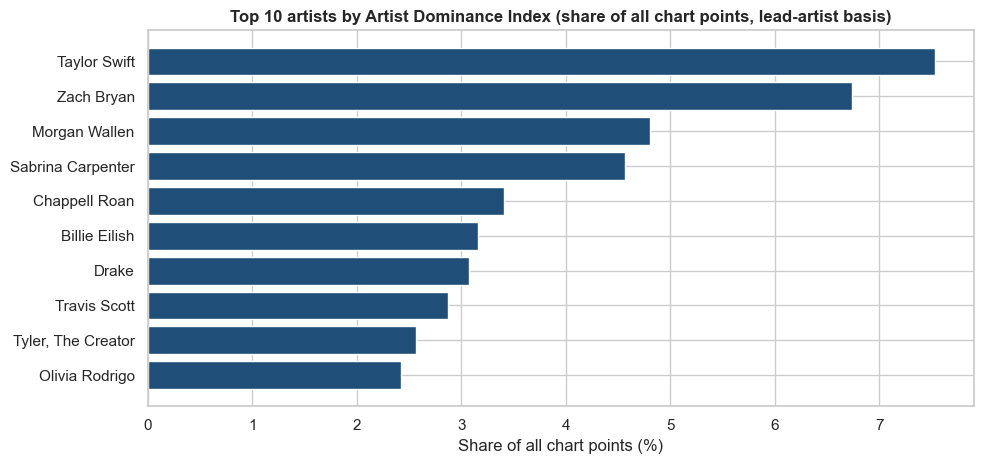

In [24]:
# Every daily row is counted once for EACH artist on the song
artist_rows = df[["date", "track_id", "position", "chart_points", "in_top10", "is_number_one"]].merge(
    bridge[["track_id", "artist_name", "is_primary"]], on="track_id", how="inner")

artists = artist_rows.groupby("artist_name").agg(
    unique_tracks=("track_id", "nunique"),                                  # number of unique songs
    chart_slot_days=("date", "size"),                                       # song-days (3 songs on one day = 3)
    days_present=("date", "nunique"),                                       # distinct dates with at least one song
    first_seen=("date", "min"),
    last_seen=("date", "max"),
    avg_rank=("position", "mean"),
    best_rank=("position", "min"),
    days_in_top10=("in_top10", "sum"),
    days_at_number_one=("is_number_one", "sum"),
    chart_points=("chart_points", "sum"))

as_primary = artist_rows[artist_rows["is_primary"]].groupby("artist_name").agg(
    unique_tracks_as_primary=("track_id", "nunique"),
    chart_slot_days_primary=("date", "size"),
    chart_points_primary=("chart_points", "sum"))
artists = artists.join(as_primary)
for col in as_primary.columns:
    artists[col] = artists[col].fillna(0).astype(int)                       # artists who are never the lead get 0

total_points, total_slots = df["chart_points"].sum(), len(df)
adi_primary = artists["chart_points_primary"] / total_points * 100          # shares (%) that add up to exactly 100
adi_all     = artists["chart_points"] / total_points * 100
assert np.isclose(adi_primary.sum(), 100.0), "primary-basis shares must add up to 100%"

artists["dominance_index_primary"]     = adi_primary.round(4)
artists["dominance_index_all_credits"] = adi_all.round(4)
artists["share_of_slots_primary_pct"]  = (artists["chart_slot_days_primary"] / total_slots * 100).round(4)
artists["avg_rank"] = artists["avg_rank"].round(2)
artists = artists.reset_index()

hhi = float((adi_primary ** 2).sum())
print(f"Artists: {len(artists)} | primary-basis shares add up to {adi_primary.sum():.2f}% | all-credits shares add up to {adi_all.sum():.1f}%")
print(f"Top 10 artists hold {adi_primary.nlargest(10).sum():.1f}% of all chart points | HHI = {hhi:,.0f} (below 1,500 = unconcentrated)")

top10 = artists.sort_values("dominance_index_primary", ascending=False).head(10)
display(top10[["artist_name", "unique_tracks", "days_present", "avg_rank", "best_rank", "days_in_top10",
               "dominance_index_primary", "dominance_index_all_credits"]])

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(top10["artist_name"][::-1], top10["dominance_index_primary"][::-1], color=COLORS["primary"])
ax.set_title("Top 10 artists by Artist Dominance Index (share of all chart points, lead-artist basis)")
ax.set_xlabel("Share of all chart points (%)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p2_artist_dominance_top10.png", dpi=150)
plt.show()

### Step 5.3 - The calendar table (one row for every calendar day)

**What this code is:** A table with **one row for every calendar day** from the first to the last date: 559 rows, including the 4 days without a snapshot. Columns: `date`, a numeric `date_key` (such as 20240518), calendar attributes, `season`, and `has_snapshot` (False for the 4 missing days).

**Why we need it:** Power BI's time-intelligence functions (year-to-date, same-period-last-month and so on) require a **continuous** date table with no holes. If we used only the dates that appear in the data, the 4 missing days would silently break those calculations. It is also the standard "date dimension" in a star schema.

**What will happen:** Python builds the calendar, adds the same calendar attributes as before, adds the northern-hemisphere season (Winter = Dec-Feb, Spring = Mar-May, Summer = Jun-Aug, Fall = Sep-Nov) and joins the snapshot numbers.

**Expected outcome:** **559 rows**, of which **555** have a snapshot. The 4 days with `has_snapshot = False` are 2025-03-14, 2025-03-25, 2025-07-11 and 2025-08-13.

**Motive:** A proper date dimension is the backbone of every Power BI report.

In [25]:
calendar = pd.DataFrame({"date": pd.date_range(df["date"].min(), df["date"].max(), freq="D")})
calendar = calendar.merge(snapshots, on="date", how="left")                  # adds snapshot_index and days_since_prev_snapshot
calendar["has_snapshot"]  = calendar["snapshot_index"].notna()
calendar["snapshot_index"] = calendar["snapshot_index"].astype("Int64")
calendar["days_since_prev_snapshot"] = calendar["days_since_prev_snapshot"].astype("Int64")

calendar["date_key"]    = calendar["date"].dt.strftime("%Y%m%d").astype(int)
calendar["year"]        = calendar["date"].dt.year
calendar["month"]       = calendar["date"].dt.month
calendar["month_name"]  = calendar["date"].dt.month_name()
calendar["year_month"]  = calendar["date"].dt.strftime("%Y-%m")
calendar["quarter"]     = calendar["date"].dt.quarter
calendar["iso_week"]    = calendar["date"].dt.isocalendar().week.astype(int)
calendar["day_of_week"] = calendar["date"].dt.dayofweek + 1
calendar["day_name"]    = calendar["date"].dt.day_name()
calendar["is_weekend"]  = calendar["day_of_week"] >= 6
calendar["season"] = np.select([calendar["month"].isin([12, 1, 2]), calendar["month"].isin([3, 4, 5]),
                                calendar["month"].isin([6, 7, 8])], ["Winter", "Spring", "Summer"], default="Fall")

print(f"Calendar rows: {len(calendar)} | with a snapshot: {int(calendar['has_snapshot'].sum())}")
print("Days without a snapshot:", [d.strftime("%Y-%m-%d") for d in calendar.loc[~calendar["has_snapshot"], "date"]])
display(calendar.head(4))

Calendar rows: 559 | with a snapshot: 555
Days without a snapshot: ['2025-03-14', '2025-03-25', '2025-07-11', '2025-08-13']


,date,snapshot_index,days_since_prev_snapshot,has_snapshot,date_key,year,month,month_name,year_month,quarter,iso_week,day_of_week,day_name,is_weekend,season
0,2024-05-18,1,<NA>,True,20240518,2024,5,May,2024-05,2,20,6,Saturday,True,Spring
1,2024-05-19,2,1,True,20240519,2024,5,May,2024-05,2,20,7,Sunday,True,Spring
2,2024-05-20,3,1,True,20240520,2024,5,May,2024-05,2,21,1,Monday,False,Spring
3,2024-05-21,4,1,True,20240521,2024,5,May,2024-05,2,21,2,Tuesday,False,Spring


### Step 5.4 - The daily summary: entries, exits and chart turnover

**What this code is:** One row per snapshot date (555 rows) with daily measures of the *whole* chart: how many songs **entered** (new or re-entry), how many **exited**, the **turnover rate**, the average popularity, the **Explicit Content Share** (a KPI of the brief), the share of collaborations, the share of singles and the number of distinct artists.

**Why we need it:** This table answers "how stable is the chart *as a whole*?", which is the other half of the "stability vs volatility" question. We also flag **high-turnover days** with a statistical rule: a day is "high turnover" if its entries exceed the **upper far-out fence** `Q3 + 3 x IQR` (Tukey's rule for extreme values), instead of choosing a number by gut feeling.

**What will happen:** Python counts entries and exits per day (an exit becomes visible on the *next* snapshot), computes the fence, flags the unusual days and draws a timeline. A table lists the biggest days with the song at #1, so that you can see *why* they are unusual.

**Expected outcome:** On a normal day only 1-4 songs enter (median 2, Q3 = 4), so the fence is **13 entries** and **22 of the 555 days** are flagged. The biggest are **2024-12-28 (49 entries)**, **2025-04-21 (32)** and **2024-07-29 (30)**. On 2024-12-28 the chart switches from an all-Christmas list (all 50 songs on 2024-12-27 were Christmas songs) to the regular chart: only 1 song stays. On the other big days the song at #1 comes from one artist's brand-new album (*Fortnight* by Taylor Swift on 2025-04-21, *MELTDOWN* by Travis Scott on 2024-07-29). Entries equal exits on every day.

**Motive:** These days are not errors; they are real shocks. In Phase 4 we will analyze them separately so that they do not distort the "typical" behaviour of the chart.

Entries per day: median 2 | Q1 1 | Q3 4 | far-out fence 13
High-turnover days (more than 13 entries): 22 of 555
OK  entries equal exits on every day



,entries,song_at_number_1
date,,
2024-12-28,49,Lovin On Me by Jack Harlow
2025-04-21,32,Fortnight (feat. Post Malone) by Taylor Swift
2024-07-29,30,MELTDOWN by Travis Scott
2025-03-24,27,Like That by Future & Metro Boomin
2024-07-02,27,vampire by Olivia Rodrigo
2024-10-29,24,Is It Over Now? (Taylor's Version) (From The Vault) by T...
2025-07-06,24,A Bar Song (Tipsy) by Shaboozey
2024-07-09,23,Mine (Taylor's Version) by Taylor Swift


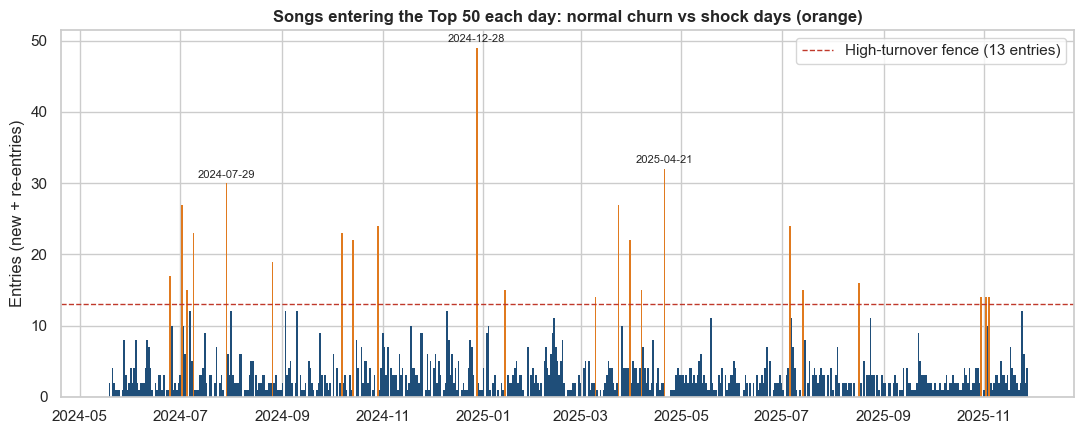

In [26]:
daily = df.groupby("date").agg(
    snapshot_index=("snapshot_index", "first"),
    unique_tracks=("track_id", "nunique"),
    avg_popularity=("popularity_clean", "mean"),
    median_popularity=("popularity_clean", "median"),
    explicit_share=("is_explicit", "mean"),                                  # KPI: Explicit Content Share (0 to 1)
    collab_share=("is_collab", "mean"),
    avg_duration_min=("duration_min", "mean"),
    unique_primary_artists=("primary_artist", "nunique"))
daily["single_share"] = df.assign(is_single=df["release_format"].eq("Single")).groupby("date")["is_single"].mean()

daily["new_entries"] = df[df["movement"] == "New entry"].groupby("date").size().reindex(daily.index, fill_value=0)
daily["re_entries"]  = df[df["movement"] == "Re-entry"].groupby("date").size().reindex(daily.index, fill_value=0)

exits_by_snapshot = df[df["exits_next_snapshot"]].groupby("snapshot_index").size()
exits_by_snapshot.index = exits_by_snapshot.index + 1                        # the exit is visible on the NEXT snapshot
daily["exits"] = daily["snapshot_index"].map(exits_by_snapshot).fillna(0).astype(int)

entries = daily["new_entries"] + daily["re_entries"]
assert (entries.iloc[1:] == daily["exits"].iloc[1:]).all(), "entries and exits must match on every day"
daily["turnover_rate_pct"] = (entries / 50 * 100).round(1)

q1, q3 = entries.iloc[1:].quantile([0.25, 0.75])                             # day 1 cannot have entries, so it is skipped
fence = q3 + 3 * (q3 - q1)                                                   # Tukey's upper far-out fence
daily["is_high_turnover_day"] = entries > fence
daily = daily.round({"avg_popularity": 2, "median_popularity": 2, "explicit_share": 4, "collab_share": 4,
                     "single_share": 4, "avg_duration_min": 3})

print(f"Entries per day: median {entries.iloc[1:].median():.0f} | Q1 {q1:.0f} | Q3 {q3:.0f} | far-out fence {fence:.0f}")
print(f"High-turnover days (more than {fence:.0f} entries): {int(daily['is_high_turnover_day'].sum())} of {len(daily)}")
print("OK  entries equal exits on every day\n")

top_days = entries.sort_values(ascending=False).head(8).rename("entries").to_frame()
top_days["song_at_number_1"] = df[df["position"] == 1].set_index("date")["track_label"].reindex(top_days.index)
display(top_days)

fig, ax = plt.subplots()
colors = np.where(daily["is_high_turnover_day"], COLORS["accent"], COLORS["primary"])
ax.bar(daily.index, entries, color=colors, width=1.0, edgecolor="none", linewidth=0)   # no white edge: the bars are very thin
ax.axhline(fence, color=COLORS["bad"], ls="--", lw=1, label=f"High-turnover fence ({fence:.0f} entries)")
for day, value in entries.nlargest(3).items():
    ax.annotate(day.strftime("%Y-%m-%d"), (day, value), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)
ax.set_title("Songs entering the Top 50 each day: normal churn vs shock days (orange)")
ax.set_ylabel("Entries (new + re-entries)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "p2_daily_entries.png", dpi=150)
plt.show()
daily = daily.reset_index()

## Section 6 - Quality gate and save

### Step 6.1 - Assemble the final tables

**What this code is:** Choosing, for each output table, exactly which columns it contains and in which order. We build **seven tables**:

| Table | One row per | Rows | Used for |
|---|---|---|---|
| `playlist_daily` | song on one day (wide) | 27,750 | Python analysis, statistics, Streamlit |
| `fact_chart_daily` | song on one day (narrow) | 27,750 | Power BI fact table |
| `dim_track` | song | 944 | Song KPIs |
| `dim_artist` | artist | 283 | Artist KPIs and the Dominance Index |
| `bridge_track_artist` | song-artist pair | 1,105 | Links songs and artists (many-to-many) |
| `dim_date` | calendar day | 559 | Continuous date table |
| `daily_summary` | snapshot date | 555 | Chart-level daily measures |

**Why we need it:** The wide table is convenient for analysis; the narrow fact table plus the dimension tables form a **star schema**, which is how Power BI (and every data warehouse) likes its data. Listing the columns explicitly also means that no temporary helper column can leak into the outputs.

**What will happen:** Python selects the columns, sorts each table sensibly and prints the shape of every table.

**Expected outcome:** The shapes in the table above; `playlist_daily` has 54 columns, `fact_chart_daily` 21 and `dim_track` 47.

**Motive:** Clean, intentional outputs: every column is there on purpose.

In [27]:
playlist_cols = [
    # when
    "date", "snapshot_index", "days_since_prev_snapshot", "year", "month", "month_name", "year_month", "quarter",
    "iso_week", "day_of_week", "day_name", "is_weekend",
    # which song
    "track_id", "track_label", "song_clean", "artist_credit", "primary_artist", "artist_count", "artists_all", "is_collab",
    # chart position
    "position", "rank_tier", "in_top10", "in_top20", "is_number_one", "chart_points",
    # popularity
    "popularity", "popularity_clean", "popularity_was_zero", "popularity_fill_method", "popularity_trend_7d",
    # rank movement
    "prev_position", "rank_change", "movement", "rank_gain_7d", "avg_rank_7d", "rank_volatility_7d",
    # life on the chart
    "stint_no", "stint_key", "days_in_stint", "stint_length", "is_stint_start", "is_stint_end", "exits_next_snapshot",
    "chart_day_number", "calendar_age_days",
    # song attributes as they were on that day
    "duration_ms", "duration_min", "album_type", "release_format", "total_tracks", "release_size_band", "is_explicit",
    "album_cover_url",
]
fact_cols = [
    "date", "track_id", "position", "chart_points", "popularity_clean", "popularity_trend_7d", "popularity_fill_method",
    "rank_change", "rank_gain_7d", "avg_rank_7d", "rank_volatility_7d", "movement", "rank_tier", "in_top10", "in_top20",
    "is_number_one", "chart_day_number", "days_in_stint", "is_stint_start", "is_stint_end", "is_explicit",
]
track_cols = [
    "track_id", "track_label", "song_clean", "artist_credit", "primary_artist", "artist_count", "is_collab", "artists_all",
    "days_on_chart", "first_seen", "last_seen", "span_days", "span_snapshots", "presence_ratio", "n_runs", "longest_run_days",
    "avg_rank", "median_rank", "best_rank", "worst_rank", "rank_volatility_index", "avg_daily_rank_move",
    "days_in_top10", "days_in_top20", "days_at_number_one", "chart_points", "entry_rank", "exit_rank", "peak_date", "days_to_peak",
    "avg_popularity", "peak_popularity", "popularity_std",
    "on_chart_at_window_start", "on_chart_at_window_end", "run_status", "longevity_class", "reached_top10", "reached_number_one",
    "duration_ms", "duration_min", "album_type", "release_format", "total_tracks", "release_size_band", "is_explicit",
    "album_cover_url",
]
artist_cols = [
    "artist_name", "unique_tracks", "unique_tracks_as_primary", "chart_slot_days", "chart_slot_days_primary", "days_present",
    "first_seen", "last_seen", "avg_rank", "best_rank", "days_in_top10", "days_at_number_one", "chart_points",
    "chart_points_primary", "dominance_index_primary", "dominance_index_all_credits", "share_of_slots_primary_pct",
]
bridge_cols = ["track_id", "artist_name", "artist_order", "is_primary"]
date_cols = ["date", "date_key", "has_snapshot", "snapshot_index", "days_since_prev_snapshot", "year", "month", "month_name",
             "year_month", "quarter", "iso_week", "day_of_week", "day_name", "is_weekend", "season"]
summary_cols = ["date", "snapshot_index", "unique_tracks", "new_entries", "re_entries", "exits", "turnover_rate_pct",
                "is_high_turnover_day", "avg_popularity", "median_popularity", "explicit_share", "collab_share", "single_share",
                "avg_duration_min", "unique_primary_artists"]

tables = {
    "playlist_daily":      df.sort_values(["date", "position"])[playlist_cols].reset_index(drop=True),
    "fact_chart_daily":    df.sort_values(["date", "position"])[fact_cols].reset_index(drop=True),
    "dim_track":           songs.reset_index()[track_cols].sort_values("track_id").reset_index(drop=True),
    "dim_artist":          artists[artist_cols].sort_values("dominance_index_primary", ascending=False).reset_index(drop=True),
    "bridge_track_artist": bridge[bridge_cols],
    "dim_date":            calendar[date_cols],
    "daily_summary":       daily[summary_cols],
}

for name, table in tables.items():
    print(f"{name:<22} {table.shape[0]:>7,} rows x {table.shape[1]:>2} columns")

playlist_daily          27,750 rows x 54 columns
fact_chart_daily        27,750 rows x 21 columns
dim_track                  944 rows x 47 columns
dim_artist                 283 rows x 17 columns
bridge_track_artist      1,105 rows x  4 columns
dim_date                   559 rows x 15 columns
daily_summary              555 rows x 15 columns


### Step 6.2 - The quality gate: automatic tests on the finished tables

**What this code is:** A list of 20 automatic tests (a *quality gate*) that the finished tables must pass before we save anything. Examples: every date has 50 ranks, no song appears twice on one date, the rank change really equals "yesterday minus today" (recalculated by a completely different method), the artist shares add up to 100%, entries equal exits.

**Why we need it:** Phase 1 tested the *raw* data. Phase 2 *created* hundreds of thousands of new values with a lot of code, and code can have bugs. The gate is the safety net: it does not trust our own calculations, it re-checks them independently.

**What will happen:** Python runs each test, prints a PASS/FAIL table and stops with an error if any test fails.

**Expected outcome:** **20 of 20 tests PASS**.

**Motive:** Trust, but verify. When someone asks "how do you know these numbers are right?", the answer is this table.

In [28]:
gate_results = []


def gate(name, passed, detail=""):
    """Record one automatic test."""
    gate_results.append({"test": name, "status": "PASS" if bool(passed) else "FAIL", "detail": detail})


pd_ = tables["playlist_daily"]
dt_, da_, br_, dd_, ds_ = tables["dim_track"], tables["dim_artist"], tables["bridge_track_artist"], tables["dim_date"], tables["daily_summary"]

gate("555 dates x 50 rows = 27,750 rows", len(pd_) == 555 * 50 and pd_.groupby("date").size().eq(50).all(), f"{len(pd_):,} rows")
gate("(date, position) is unique", not pd_.duplicated(["date", "position"]).any())
gate("(date, track_id) is unique: no song twice on one day", not pd_.duplicated(["date", "track_id"]).any())
gate("Every date holds all positions 1-50", pd_.groupby("date")["position"].nunique().eq(50).all())
gate("snapshot_index runs 1..555 without holes", sorted(pd_["snapshot_index"].unique()) == list(range(1, 556)))
gate("No missing values in the key columns", pd_[["date", "track_id", "position", "track_label", "stint_key", "movement"]].notna().all().all())

gate("popularity_clean stays inside 0-100", pd_["popularity_clean"].dropna().between(1, 100).all())
gate("Only the 'unfilled' rows have no clean popularity",
     pd_["popularity_clean"].isna().sum() == (pd_["popularity_fill_method"] == "unfilled").sum(),
     f"{int(pd_['popularity_clean'].isna().sum())} empty values")
gate("popularity_clean equals the original wherever the original was not zero",
     (pd_.loc[~pd_["popularity_was_zero"], "popularity_clean"] == pd_.loc[~pd_["popularity_was_zero"], "popularity"]).all())

# Independent recalculation of yesterday's position (a different method from the one we used)
yesterday = pd_[["track_id", "snapshot_index", "position"]].copy()
yesterday["snapshot_index"] += 1
yesterday = yesterday.rename(columns={"position": "prev_position_check"})
check = pd_[["track_id", "snapshot_index", "prev_position"]].merge(yesterday, on=["track_id", "snapshot_index"], how="left")
gate("prev_position equals an independent recalculation", (check["prev_position"].fillna(-1) == check["prev_position_check"].fillna(-1)).all())
gate("rank_change = prev_position - position",
     ((pd_["prev_position"] - pd_["position"]).fillna(-999) == pd_["rank_change"].fillna(-999)).all())
gate("Every row has exactly one movement label", pd_["movement"].isin(["Up", "Down", "Same", "New entry", "Re-entry", "Chart start"]).all())
gate("Entries equal exits on every day", (ds_["new_entries"] + ds_["re_entries"]).iloc[1:].eq(ds_["exits"].iloc[1:]).all())

gate("dim_track: one row per song, 944 songs", dt_["track_id"].is_unique and len(dt_) == 944)
gate("Sum of days_on_chart equals the number of daily rows", dt_["days_on_chart"].sum() == len(pd_))
gate("best_rank <= avg_rank <= worst_rank for every song",
     ((dt_["best_rank"] <= dt_["avg_rank"]) & (dt_["avg_rank"] <= dt_["worst_rank"])).all())
gate("Rank Volatility Index is never negative", (dt_["rank_volatility_index"].dropna() >= 0).all())
gate("Every song has exactly one primary artist in the bridge", br_.groupby("track_id")["is_primary"].sum().eq(1).all())
gate("Artist Dominance Index (primary basis) adds up to 100%", abs(da_["dominance_index_primary"].sum() - 100) < 0.05,
     f"{da_['dominance_index_primary'].sum():.3f}%")
gate("dim_date is continuous: 559 days, 555 with a snapshot",
     len(dd_) == 559 and dd_["date"].diff().dropna().eq(pd.Timedelta(days=1)).all() and int(dd_["has_snapshot"].sum()) == 555)

gate_df = pd.DataFrame(gate_results)
display(gate_df)
print(f"{(gate_df['status'] == 'PASS').sum()} of {len(gate_df)} tests passed")
assert (gate_df["status"] == "PASS").all(), "at least one quality-gate test failed - read the table above"

,test,status,detail
0,"555 dates x 50 rows = 27,750 rows",PASS,"27,750 rows"
1,"(date, position) is unique",PASS,
2,"(date, track_id) is unique: no song twice on one day",PASS,
3,Every date holds all positions 1-50,PASS,
4,snapshot_index runs 1..555 without holes,PASS,
5,No missing values in the key columns,PASS,
6,popularity_clean stays inside 0-100,PASS,
7,Only the 'unfilled' rows have no clean popularity,PASS,18 empty values
8,popularity_clean equals the original wherever the origin...,PASS,
9,prev_position equals an independent recalculation,PASS,


20 of 20 tests passed


### Step 6.3 - The data dictionary and the KPI dictionary

**What this code is:** Two documents produced by code. The **data dictionary** lists every column of every table with its type, a plain-English definition and an example value. The **KPI dictionary** lists the project's KPIs with their formula and meaning.

**Why we need it:** Six months from now (or in an interview, or in the research paper) nobody remembers what `rank_gain_7d` means. A dictionary also forces us to *define* every number we produce. As a safety net, the code **stops if any column has no definition**.

**What will happen:** Python looks up the definition of each column (table-specific wording first, then the general one), builds the two tables and checks that nothing is undocumented.

**Expected outcome:** A data dictionary with **one row for each column of each table** (173 rows) and a KPI dictionary with 11 KPIs. The message `OK  every column is documented`.

**Motive:** Documentation is part of the deliverable; this makes it automatic and always up to date.

In [29]:
COMMON = {
    # ---- time ----
    "date": "Calendar date of the playlist snapshot, kept exactly as provided in the source file.",
    "snapshot_index": "Order number of the snapshot: 1 for the first date, 555 for the last. Missing calendar days get no number.",
    "days_since_prev_snapshot": "Calendar days since the previous snapshot (1 normally, 2 right after a missing day; empty for the first).",
    "year": "Calendar year.", "month": "Calendar month number (1-12).", "month_name": "Calendar month name.",
    "year_month": "Year and month as text, e.g. 2024-05 (sorts correctly).", "quarter": "Calendar quarter (1-4).",
    "iso_week": "ISO week number of the year.", "day_of_week": "Day of the week, Monday = 1 ... Sunday = 7.",
    "day_name": "Name of the weekday.", "is_weekend": "True for Saturday and Sunday.",
    "date_key": "Date as a whole number yyyymmdd, e.g. 20240518 (handy join key).",
    "has_snapshot": "True if the playlist was captured on this calendar day; False for the 4 missing days.",
    "season": "Northern-hemisphere season: Winter (Dec-Feb), Spring (Mar-May), Summer (Jun-Aug), Fall (Sep-Nov).",
    # ---- song identity ----
    "track_id": "Unique id of a song after resolving title and artist-credit variants (Phase 1, Step 6.5).",
    "track_label": "Readable name: song title + 'by' + artist credit. Unique per song.",
    "song_clean": "Cleaned song title (single spaces, one spelling per song).",
    "artist_credit": "Fullest artist credit seen for the song; artists joined with ' & '.",
    "primary_artist": "First (lead) artist of the credit.",
    "artist_count": "Number of artists in the credit.",
    "artists_all": "All artists of the credit joined with ' | ' (easy to split into a list).",
    "is_collab": "True when the song has two or more artists.",
    # ---- chart position ----
    "position": "Playlist rank on that day: 1 = top, 50 = bottom.",
    "rank_tier": "Rank group of the row: Top 10, 11-20 or 21-50.",
    "in_top10": "True when position is 10 or better.", "in_top20": "True when position is 20 or better.",
    "is_number_one": "True when position = 1.",
    "chart_points": "51 minus position (rank 1 = 50 points ... rank 50 = 1 point); the basis of the Artist Dominance Index.",
    # ---- popularity ----
    "popularity": "Popularity score from the source file (0-100). A 0 means 'not yet scored'; see popularity_clean.",
    "popularity_clean": "Popularity after repairing zeros (run interpolation, then song median; empty if no real value exists).",
    "popularity_was_zero": "True when the source popularity value was 0.",
    "popularity_fill_method": "How popularity_clean was obtained: original, interpolated_in_run, song_median or unfilled.",
    "popularity_trend_7d": "Popularity Trend Score: 7-day rolling average of popularity_clean inside the same chart run.",
    # ---- movement ----
    "prev_position": "Position on the immediately preceding snapshot (empty on the first day of a run).",
    "rank_change": "prev_position minus position. Positive = climbed, negative = fell, 0 = unchanged.",
    "movement": "Up, Down, Same, New entry, Re-entry or Chart start.",
    "rank_gain_7d": "Position 7 snapshots ago minus position now (positive = climbed over the week); empty unless present on all 7.",
    "avg_rank_7d": "7-day rolling average of position inside the same run.",
    "rank_volatility_7d": "7-day rolling standard deviation of position inside the same run (needs at least 3 days).",
    # ---- life on the chart ----
    "stint_no": "Run number of the song: 1 for its first unbroken streak on the chart, 2 for the next, and so on.",
    "stint_key": "Unique id of one run: track_id-run number.",
    "days_in_stint": "Day number inside the current run (1 = first day of the run).",
    "stint_length": "Total length in days of the run this row belongs to.",
    "is_stint_start": "True on the first day of a run (an entry or re-entry).",
    "is_stint_end": "True on the last day of a run.",
    "exits_next_snapshot": "True when the song is on the chart today but absent on the next snapshot (a real exit).",
    "chart_day_number": "Chart days accumulated so far by the song (1 = debut day).",
    "calendar_age_days": "Calendar days since the song's first appearance.",
    # ---- attributes ----
    "duration_ms": "Song duration in milliseconds.", "duration_min": "Song duration in minutes (the brief's 'Duration in minutes').",
    "album_type": "Album type from the source: single, album or compilation.",
    "release_format": "Single, or Album (album and compilation together).",
    "total_tracks": "Number of tracks on the release.",
    "release_size_band": "Release size group: 1 track, 2-3, 4-7, 8-15, 16-40 or 41+.",
    "is_explicit": "Explicit-content flag.", "album_cover_url": "Link to the artwork image.",
    # ---- song KPIs ----
    "days_on_chart": "KPI Days on Chart: number of snapshots on which the song appeared.",
    "first_seen": "First date the song appeared.", "last_seen": "Last date the song appeared.",
    "span_days": "Calendar days from first to last appearance, inclusive.",
    "span_snapshots": "Snapshots from first to last appearance, inclusive.",
    "presence_ratio": "days_on_chart divided by span_snapshots: 1.0 = never left the chart, near 0 = many short visits.",
    "n_runs": "Number of separate chart runs.", "longest_run_days": "Length of the longest unbroken run in days.",
    "avg_rank": "KPI Average Rank: mean position over the song's chart days (lower is better).",
    "median_rank": "Median position.", "best_rank": "KPI Best Rank Achieved: the smallest position reached.",
    "worst_rank": "Largest (worst) position reached.",
    "rank_volatility_index": "KPI Rank Volatility Index: standard deviation of position (empty for songs with a single day).",
    "avg_daily_rank_move": "Average absolute day-to-day rank change (day-to-day jumpiness).",
    "days_in_top10": "Days in the Top 10.", "days_in_top20": "Days in the Top 20.", "days_at_number_one": "Days at #1.",
    "entry_rank": "Position on the first chart day.", "exit_rank": "Position on the last chart day.",
    "peak_date": "First date the best rank was reached.", "days_to_peak": "Calendar days from first appearance to peak_date.",
    "avg_popularity": "Average of popularity_clean.", "peak_popularity": "Highest popularity_clean.",
    "popularity_std": "Standard deviation of popularity_clean (lower = more stable).",
    "on_chart_at_window_start": "True when the song was already on the chart on the first snapshot (history before our data is unknown).",
    "on_chart_at_window_end": "True when the song is still on the chart on the last snapshot (its run is not finished).",
    "run_status": "Complete history observed, Already on chart at start, Still on chart at end, or On chart the whole window.",
    "longevity_class": "Flash (1-3 days), Short (4-14), Medium (15-60), Long (61-180) or Evergreen (181+).",
    "reached_top10": "True when the song reached position 10 or better.", "reached_number_one": "True when the song reached #1.",
    # ---- bridge ----
    "artist_name": "Individual artist name (standardized spelling).",
    "artist_order": "Position of the artist inside the credit (1 = lead).", "is_primary": "True for the lead artist.",
    # ---- daily summary ----
    "unique_tracks": "Distinct songs on the date (always 50).",
    "new_entries": "Songs appearing in our data for the first time on this date.",
    "re_entries": "Songs returning after being off the chart.",
    "exits": "Songs that were on the previous snapshot but are not on this one.",
    "turnover_rate_pct": "(new_entries + re_entries) / 50 x 100.",
    "is_high_turnover_day": "True when entries exceed Tukey's upper far-out fence (Q3 + 3 x IQR).",
    "median_popularity": "Median popularity_clean of the 50 songs.",
    "explicit_share": "KPI Explicit Content Share: share of the 50 rows flagged explicit (0-1).",
    "collab_share": "Share of the 50 rows that are collaborations (0-1).",
    "single_share": "Share of the 50 rows that are singles (0-1).",
    "avg_duration_min": "Average song duration in minutes.",
    "unique_primary_artists": "Distinct lead artists on the date.",
}

SONG_LEVEL = " Song level: the most frequent value across the song's chart days (ties: most recent)."
OVERRIDES = {
    ("dim_track", "duration_ms"): COMMON["duration_ms"] + SONG_LEVEL,
    ("dim_track", "duration_min"): COMMON["duration_min"] + SONG_LEVEL,
    ("dim_track", "album_type"): COMMON["album_type"] + SONG_LEVEL,
    ("dim_track", "release_format"): COMMON["release_format"] + SONG_LEVEL,
    ("dim_track", "total_tracks"): COMMON["total_tracks"] + SONG_LEVEL,
    ("dim_track", "release_size_band"): COMMON["release_size_band"] + SONG_LEVEL,
    ("dim_track", "is_explicit"): COMMON["is_explicit"] + SONG_LEVEL,
    ("dim_track", "album_cover_url"): "Link to the song's latest artwork image.",
    ("dim_track", "chart_points"): "Total chart points earned by the song (sum of 51 - position).",
    ("dim_artist", "unique_tracks"): "KPI: number of unique songs the artist is credited on.",
    ("dim_artist", "first_seen"): "First date the artist had a song on the chart.",
    ("dim_artist", "last_seen"): "Last date the artist had a song on the chart.",
    ("dim_artist", "avg_rank"): "Mean position over all of the artist's song-days (every credited artist counts).",
    ("dim_artist", "best_rank"): "Best position reached by any of the artist's songs.",
    ("dim_artist", "days_in_top10"): "Song-days the artist had in the Top 10.",
    ("dim_artist", "days_at_number_one"): "Song-days the artist had at #1.",
    ("dim_artist", "chart_points"): "Total chart points of all songs the artist is credited on.",
    ("dim_artist", "unique_tracks_as_primary"): "Songs on which the artist is the lead artist.",
    ("dim_artist", "chart_slot_days"): "Song-days on the chart (three songs on one day count as three).",
    ("dim_artist", "chart_slot_days_primary"): "Song-days where the artist is the lead artist.",
    ("dim_artist", "days_present"): "KPI: distinct dates on which the artist had at least one song on the chart.",
    ("dim_artist", "chart_points_primary"): "Chart points of songs where the artist is the lead artist.",
    ("dim_artist", "dominance_index_primary"): "KPI Artist Dominance Index (%): share of all chart points earned as lead artist; adds up to 100.",
    ("dim_artist", "dominance_index_all_credits"): "Artist Dominance Index (%) when every credited artist receives the song's full points; adds up to more than 100.",
    ("dim_artist", "share_of_slots_primary_pct"): "Share (%) of all 27,750 chart slots held as lead artist.",
    ("daily_summary", "avg_popularity"): "Average popularity_clean of the 50 songs on the date.",
    ("daily_summary", "snapshot_index"): COMMON["snapshot_index"],
}


def definition(table, column):
    """Table-specific wording first, then the general one."""
    return OVERRIDES.get((table, column), COMMON.get(column))


rows = []
for table_name, table in tables.items():
    for col in table.columns:
        example = table[col].dropna()
        rows.append({"table": table_name, "column": col, "dtype": str(table[col].dtype),
                     "definition": definition(table_name, col),
                     "example": str(example.iloc[0])[:45] if len(example) else ""})
data_dictionary = pd.DataFrame(rows)

undocumented = data_dictionary[data_dictionary["definition"].isna()]
assert undocumented.empty, f"columns without a definition: {undocumented[['table', 'column']].values.tolist()}"
print(f"OK  every column is documented ({len(data_dictionary)} rows in the data dictionary)")

kpi_dictionary = pd.DataFrame([
    ("Days on Chart", "dim_track.days_on_chart", "Count of snapshots on which the song appears", "Longevity indicator"),
    ("Average Rank", "dim_track.avg_rank", "Mean of position over the song's chart days", "Overall performance; lower is better"),
    ("Best Rank Achieved", "dim_track.best_rank", "Minimum of position", "Peak performance"),
    ("Rank Volatility Index", "dim_track.rank_volatility_index", "Standard deviation of position over the song's chart days", "Stability: higher = less stable"),
    ("Average Daily Rank Move", "dim_track.avg_daily_rank_move", "Mean of |rank_change| from one snapshot to the next", "Day-to-day jumpiness"),
    ("Popularity Score Trend", "playlist_daily.popularity_trend_7d", "7-day rolling mean of popularity_clean inside a run", "Listener engagement over time"),
    ("Artist Dominance Index", "dim_artist.dominance_index_primary", "Artist's chart points / all chart points x 100; points = 51 - position", "Market presence; adds up to 100%"),
    ("Explicit Content Share", "daily_summary.explicit_share", "Share of the 50 daily rows with is_explicit = True", "Content strategy"),
    ("Presence Ratio", "dim_track.presence_ratio", "days_on_chart / snapshots between first and last appearance", "1.0 = never left the chart"),
    ("Turnover Rate", "daily_summary.turnover_rate_pct", "(new entries + re-entries) / 50 x 100", "How much of the chart changed that day"),
    ("Longevity Class", "dim_track.longevity_class", "Flash / Short / Medium / Long / Evergreen by days_on_chart", "Segmentation of songs"),
], columns=["kpi", "where_to_find_it", "formula", "interpretation"])
display(kpi_dictionary)

OK  every column is documented (173 rows in the data dictionary)


,kpi,where_to_find_it,formula,interpretation
0,Days on Chart,dim_track.days_on_chart,Count of snapshots on which the song appears,Longevity indicator
1,Average Rank,dim_track.avg_rank,Mean of position over the song's chart days,Overall performance; lower is better
2,Best Rank Achieved,dim_track.best_rank,Minimum of position,Peak performance
3,Rank Volatility Index,dim_track.rank_volatility_index,Standard deviation of position over the song's chart days,Stability: higher = less stable
4,Average Daily Rank Move,dim_track.avg_daily_rank_move,Mean of |rank_change| from one snapshot to the next,Day-to-day jumpiness
5,Popularity Score Trend,playlist_daily.popularity_trend_7d,7-day rolling mean of popularity_clean inside a run,Listener engagement over time
6,Artist Dominance Index,dim_artist.dominance_index_primary,Artist's chart points / all chart points x 100; points =...,Market presence; adds up to 100%
7,Explicit Content Share,daily_summary.explicit_share,Share of the 50 daily rows with is_explicit = True,Content strategy
8,Presence Ratio,dim_track.presence_ratio,days_on_chart / snapshots between first and last appearance,1.0 = never left the chart
9,Turnover Rate,daily_summary.turnover_rate_pct,(new entries + re-entries) / 50 x 100,How much of the chart changed that day


### Step 6.4 - Save everything to disk

**What this code is:** Saving each of the seven tables in two formats (Parquet and CSV) into `data/processed/`, and the documentation (cleaning log, data dictionary, KPI dictionary, quality-gate result) into `reports/`.

**Why we need it:** Phase 3 (ETL), Phase 4 (EDA), the Streamlit app and Power BI all start from these files. Parquet keeps data types exactly; CSV opens in Excel and Power BI. The CSV files use the `utf-8-sig` encoding (UTF-8 with a "byte order mark") so that Excel and Power BI display accented artist names such as *Beyonce* with the accent, and the yen sign in `¥$` correctly.

**What will happen:** Python writes 14 data files and 4 report files, and lists them with their sizes.

**Expected outcome:** Seven `.parquet` and seven `.csv` files in `data/processed/` (the biggest, `playlist_daily.csv`, is about 11 MB) and four CSV files in `reports/`.

**Motive:** The saved files are the handover from "analysis preparation" to "analysis".

In [30]:
for name, table in tables.items():
    table.to_parquet(PROCESSED_DIR / f"{name}.parquet", index=False)
    table.to_csv(PROCESSED_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

pd.DataFrame(cleaning_log).to_csv(REPORTS_DIR / "cleaning_log.csv", index=False, encoding="utf-8-sig")
data_dictionary.to_csv(REPORTS_DIR / "data_dictionary.csv", index=False, encoding="utf-8-sig")
kpi_dictionary.to_csv(REPORTS_DIR / "kpi_dictionary.csv", index=False, encoding="utf-8-sig")
gate_df.to_csv(REPORTS_DIR / "quality_gate_phase2.csv", index=False, encoding="utf-8-sig")

print("data/processed:")
for path in sorted(PROCESSED_DIR.glob("*")):
    if path.is_file() and path.suffix in (".parquet", ".csv"):
        print(f"  {path.name:<34} {path.stat().st_size / 1024:>9,.0f} KB")
print("reports:")
for name in ["cleaning_log.csv", "data_dictionary.csv", "kpi_dictionary.csv", "quality_gate_phase2.csv"]:
    print(f"  {name:<34} {(REPORTS_DIR / name).stat().st_size / 1024:>9,.0f} KB")

data/processed:
  bridge_track_artist.csv                   26 KB
  bridge_track_artist.parquet               13 KB
  daily_summary.csv                         38 KB
  daily_summary.parquet                     25 KB
  dim_artist.csv                            25 KB
  dim_artist.parquet                        30 KB
  dim_date.csv                              45 KB
  dim_date.parquet                          20 KB
  dim_track.csv                            358 KB
  dim_track.parquet                        157 KB
  fact_chart_daily.csv                   2,983 KB
  fact_chart_daily.parquet                 322 KB
  playlist_daily.csv                    10,709 KB
  playlist_daily.parquet                   887 KB
reports:
  cleaning_log.csv                           1 KB
  data_dictionary.csv                       17 KB
  kpi_dictionary.csv                         1 KB
  quality_gate_phase2.csv                    1 KB


### Step 6.5 - Round-trip test: read the saved files back

**What this code is:** Reloading every saved Parquet file and comparing it with the table in memory.

**Why we need it:** "Saved" does not prove "saved correctly". This catches lost rows, changed column names or changed data types.

**What will happen:** Python reads the seven files, compares shape, column names and the key data types, and spot-checks one value.

**Expected outcome:** Seven lines starting with `OK`, then one more `OK` for the spot-check.

**Motive:** The same habit as in Phase 1: trust, but verify.

In [31]:
for name, table in tables.items():
    back = pd.read_parquet(PROCESSED_DIR / f"{name}.parquet")
    assert back.shape == table.shape, f"{name}: shape changed"
    assert list(back.columns) == list(table.columns), f"{name}: columns changed"
    print(f"OK  {name:<22} {back.shape[0]:>7,} rows x {back.shape[1]:>2} columns")

check_daily = pd.read_parquet(PROCESSED_DIR / "playlist_daily.parquet")
check_tracks = pd.read_parquet(PROCESSED_DIR / "dim_track.parquet")
assert str(check_daily["date"].dtype).startswith("datetime64")
top_song = check_tracks.sort_values("days_on_chart", ascending=False).iloc[0]
assert top_song["days_on_chart"] == (check_daily["track_id"] == top_song["track_id"]).sum()
print(f"OK  spot-check: '{top_song['track_label']}' has {top_song['days_on_chart']} days in dim_track and in playlist_daily")

OK  playlist_daily          27,750 rows x 54 columns
OK  fact_chart_daily        27,750 rows x 21 columns
OK  dim_track                  944 rows x 47 columns
OK  dim_artist                 283 rows x 17 columns
OK  bridge_track_artist      1,105 rows x  4 columns
OK  dim_date                   559 rows x 15 columns
OK  daily_summary              555 rows x 15 columns
OK  spot-check: 'Something in the Orange by Zach Bryan' has 536 days in dim_track and in playlist_daily


## Phase 2 complete

### What you now have
- `data/interim/playlist_clean.parquet`: the cleaned checkpoint (27,750 rows)
- `data/processed/`: seven analysis-ready tables (wide table, star-schema fact + dimensions, bridge, calendar, daily summary), each as Parquet and CSV
- `reports/`: cleaning log, data dictionary, KPI dictionary, quality-gate result, and seven new charts in `reports/figures/`

### What we learned about the chart (a first taste of Phase 4)
1. **Most songs are short-lived.** Half of all songs stay 7 days or less; a few evergreens (like *Something in the Orange*, 536 days) hold the chart for more than a year.
2. **Entries are mostly re-entries.** More than half of all chart entries are songs returning, many flickering around rank 40-50.
3. **Big days are shocks.** A new album, or the end of the Christmas chart, can replace up to 49 of 50 songs in one day.
4. **Popularity zeros belong to brand-new songs** (88% on a song's first day): popularity is a *lagging* score.
5. **Dominance is spread out.** The Herfindahl-Hirschman Index is low: no single artist owns the chart.

### Check your understanding (answer in your own words)
1. Why is `rank_change` calculated as *yesterday minus today* and not the other way round?
2. Two songs both have 30 days on the chart. What do `n_runs` and `presence_ratio` tell you that `days_on_chart` cannot?
3. What is *censoring*, and why would it be unfair to call a song that debuted two weeks before the data ends "short-lived"?
4. Why do we have both `dominance_index_primary` and `dominance_index_all_credits`?

### Next: Phase 3 - the ETL pipeline and database load
Everything in Phases 1 and 2 works, but it lives in notebooks. In Phase 3 we turn the same logic into **Python scripts** (`extract`, `transform`, `load`, one command to run them all), load the tables into your database (and optionally AWS S3), create SQL views for the KPIs and add automated tests.